## 1. What this notebook computes

At zero 3-momentum the free Kohn-Sham spectrum of dirac16complex contains eight
zero modes ($\varepsilon = 0$) sitting at the fold $y = 0$, where the two halves
of a cell meet (Notebook 14b). This notebook follows what happens when the
3-momentum $k$ is switched on, at the five slices $a_{4,0} = 0, 0.5, 1, 1.5, 2$ of
the PRESCRIBED deflating history, in the corrected metric of 2026-10-16. It

- shows that the FOLD BAND (the level that grows out of the zero modes) is
  exactly $\varepsilon = \kappa k$, $\kappa = e^{-a_{4,0}}$, with the orbital
  $(e^{fMy}, 0)$ for every $k$, computes it and three other low levels for $k$
  from 0 to 4 and reproduces the Rust solver's record (figure 1);
- derives the slope $d\varepsilon/dk = \kappa$ at $k = 0$ with the
  Hellmann-Feynman rule and checks it numerically at every slice and for other
  masses and cutoffs (figure 2);
- checks the exact rescaling relation between the slices and the gap
  $\kappa\Delta k$ of the eight zero modes: along the history the band is
  redshifted while the levels away from the band rise (figure 3);
- checks the mirror symmetries of the two block types $j = \pm1$ (figure 4);
- measures the effect of the tip angle $\theta$ at the cutoff $L = 3$: the exact
  boundary identity, a small shift of the fold band (its tail at the tip is
  $e^{-2fML}$) and a large shift of the extended levels, which nothing
  suppresses toward the tip (figure 5);
- finds the particle branch, the degeneracies $4r_3(n^2)$ of the torus lattice
  and the closed shells of the free aufbau, with the particle numbers
  $N = 8, 592, 2352$ of the Revision runs (figure 6).

It prints a PASS line for every check (16 in all) and saves six figures.

## 2. How to run this notebook

**Step 1. What this notebook does and what it needs.**

Notebook 14c (The fold band: free Kohn-Sham levels at nonzero 3-momentum along the
deflating history) is the file `Revision/textbook/notebooks/14c_fold_band.ipynb` of the
repository Dirac_claude. In the corrected metric of 2026-10-16, with the fourth-order
Runge-Kutta shooting function of the Revision Rust solver (the levels found by
bisection), it computes the free Kohn-Sham levels of dirac16complex at nonzero 3-momentum
k: the fold band, which is exactly eps = kappa k with the orbital (exp(f M y), 0) for
every k, its slope kappa = exp(-a4) at k = 0 from the Hellmann-Feynman rule and
numerically, the redshift of the band along the prescribed deflating history, the exact
rescaling relation between the slices, the gap of the eight zero modes, the mirror
symmetries of the two block types, the effect of the tip angle (the exact boundary
identity; the fold band shifts little, the extended levels a lot), the particle branch,
the lattice degeneracies 4 r3(n2) and the closed shells of the free aufbau with the
particle numbers 8, 592 and 2352; it reproduces the Revision Rust solver's records of all
of these and draws six teaching figures. It needs a computer with Windows 11, macOS or
Linux, an internet connection for the installation, the program Git, and Python 3.12 or
newer (the notebooks were built with Python 3.14.5) with these packages at exactly these
versions: numpy 2.4.6, sympy 1.14.0, mpmath 1.3.0, matplotlib 3.11.0, jupyterlab 4.4.10,
nbformat 5.10.4, nbclient 0.10.2, ipykernel 7.1.0 and nbconvert 7.16.6. The notebook
itself imports numpy, sympy and matplotlib; the other packages run Jupyter, the program
that shows and runs notebooks. It does not need Rust.

**Step 2. Install Git and Python (once per computer).**

A terminal is the window in which you type commands: on Windows the app Windows
PowerShell (or Terminal), on macOS the app Terminal (it runs the shell zsh), on Linux any
terminal (it runs the shell bash). Type every command of this section into a terminal
exactly as printed, one line at a time, and press Enter after each line.

Windows: download Git from https://git-scm.com/download/win and install it with the
default choices. Download Python from https://www.python.org/downloads/ and run the
installer; in its first window tick the box "Add python.exe to PATH" before you click
"Install Now".

macOS: download Python from https://www.python.org/downloads/ and run the installer. Then
open the app Terminal and run this command, which installs Git and the compiler tools:

macOS (zsh):

    xcode-select --install

Linux (Debian or Ubuntu; other distributions have packages of the same names): run these
two commands:

Linux (bash):

    sudo apt update
    sudo apt install git python3 python3-venv

Then close the terminal and open a NEW one (a terminal opened before the installation
does not know the new programs), and check the version of Python; it must print 3.12 or a
higher number:

Windows (PowerShell):

    py -3 --version

macOS (zsh) and Linux (bash):

    python3 --version

If an older Linux prints a lower number (Ubuntu 22.04 has Python 3.10), install Python
3.12 with the following three commands, and in Step 3 type `python3.12` instead of
`python3` in the command that creates the environment:

Linux (bash), only when the version is too low:

    sudo add-apt-repository ppa:deadsnakes/ppa
    sudo apt update
    sudo apt install python3.12 python3.12-venv

**Step 3. Get the repository and install the packages (once per computer).**

The commands below download the repository (a few hundred megabytes; the folder then
needs up to about 1 GB of disk space) into the folder Dirac_claude inside your home
folder, create a private Python environment in the folder dirac-book-env inside your home
folder (a private environment is a folder with its own copy of Python and of the
packages, so that nothing else on your computer is changed), activate it (from then on
the commands `python` and `jupyter` typed in this terminal are those of the environment,
and the prompt starts with (dirac-book-env)), and install the packages at the pinned
versions (this downloads about 90 MB and takes a few minutes; the environment takes about
400 MB of disk space). If you have done this step before, for this or for another
notebook, skip it and go to Step 4; to get the newest version of the repository, run `git
pull` in the repository folder after Step 4.

Windows (PowerShell):

    cd $HOME
    git clone https://github.com/once-ere/Dirac_claude.git
    py -3 -m venv "$HOME\dirac-book-env"
    Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process -Force
    & "$HOME\dirac-book-env\Scripts\Activate.ps1"
    python -m pip install --upgrade pip
    python -m pip install numpy==2.4.6 sympy==1.14.0 mpmath==1.3.0 matplotlib==3.11.0
    python -m pip install jupyterlab==4.4.10 nbformat==5.10.4 nbclient==0.10.2
    python -m pip install ipykernel==7.1.0 nbconvert==7.16.6

The line with `Set-ExecutionPolicy` allows PowerShell to run the activation script in
this one window only; it changes nothing permanently.

macOS (zsh):

    cd ~
    git clone https://github.com/once-ere/Dirac_claude.git
    python3 -m venv ~/dirac-book-env
    source ~/dirac-book-env/bin/activate
    python -m pip install --upgrade pip
    python -m pip install numpy==2.4.6 sympy==1.14.0 mpmath==1.3.0 matplotlib==3.11.0
    python -m pip install jupyterlab==4.4.10 nbformat==5.10.4 nbclient==0.10.2
    python -m pip install ipykernel==7.1.0 nbconvert==7.16.6

Linux (bash):

    cd ~
    git clone https://github.com/once-ere/Dirac_claude.git
    python3 -m venv ~/dirac-book-env
    source ~/dirac-book-env/bin/activate
    python -m pip install --upgrade pip
    python -m pip install numpy==2.4.6 sympy==1.14.0 mpmath==1.3.0 matplotlib==3.11.0
    python -m pip install jupyterlab==4.4.10 nbformat==5.10.4 nbclient==0.10.2
    python -m pip install ipykernel==7.1.0 nbconvert==7.16.6

**Step 4. In every new terminal: activate the environment and go into the repository
folder.**

Every later step starts in the repository folder with the environment active. Run these
lines whenever you open a new terminal (they do no harm if the environment is already
active):

Windows (PowerShell):

    Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process -Force
    & "$HOME\dirac-book-env\Scripts\Activate.ps1"
    cd "$HOME\Dirac_claude"

macOS (zsh) and Linux (bash):

    source ~/dirac-book-env/bin/activate
    cd ~/Dirac_claude

**Step 5. Run the notebook in JupyterLab.**

In the repository folder, with the environment active, run these two lines (the first one
goes into the folder of the notebooks):

Windows, macOS and Linux:

    cd Revision/textbook/notebooks
    jupyter lab 14c_fold_band.ipynb

JupyterLab opens in your web browser and shows the notebook (if no browser window opens,
copy the address that starts with `http://localhost:8888/lab` from the terminal into the
address bar of your browser). The name at the top right of the notebook must read Python
3 (ipykernel). Choose the menu Run > Run All Cells. While a cell runs, the label to its
left shows `[*]`; when it has finished, the label shows a number. The notebook has
finished when the last code cell shows a number; this takes about 2 minutes on a typical
laptop. Scroll to the end and compare the last printed lines with the lines in the step
"What the notebook writes and what you must see" below. To keep the results, save the
notebook (menu File > Save Notebook). To stop JupyterLab, choose the menu File > Shut
Down, or press Ctrl+C twice in the terminal.

**Step 6. Or run the notebook without a browser (headless).**

In the repository folder, with the environment active, run:

Windows, macOS and Linux:

    cd Revision/textbook/notebooks
    jupyter nbconvert --to notebook --execute --inplace 14c_fold_band.ipynb

This runs every cell from the top to the bottom and saves the results into the notebook
file. A failed check stops it with an error message that contains AssertionError and the
name of the check. If the command ends with a line that starts with `[NbConvertApp]
Writing` and shows no error, every check passed; open the notebook with `jupyter lab
14c_fold_band.ipynb` (in the same folder, without running the cells again) to read the
printed lines and see the figures.

**Step 7. What the notebook writes and what you must see.**

The notebook writes (or overwrites) these files:

- `Revision/textbook/figures/14c.captions.json`
- `Revision/textbook/figures/14c_1_band_structure.png`
- `Revision/textbook/figures/14c_2_band_slope.png`
- `Revision/textbook/figures/14c_3_band_redshift.png`
- `Revision/textbook/figures/14c_4_block_type_mirror.png`
- `Revision/textbook/figures/14c_5_tip_angle.png`
- `Revision/textbook/figures/14c_6_closed_shells.png`

It changes no other file of the repository; running it headless or saving it in
JupyterLab also rewrites the notebook file itself. It does not use the internet while it
runs. The files it writes are the same files that are stored in the repository (on
another computer a figure may differ in a few bytes, which is harmless). To get the
stored versions back, run this command in the repository folder (it also undoes every
change you made yourself in the folder Revision/textbook):

Windows, macOS and Linux:

    git checkout -- Revision/textbook

Every check of the notebook prints a line that starts with PASS. At the end of the
notebook (the output of its last code cell) you must see exactly these lines:

    PASS all six figure files of this notebook exist
    ALL 16 CHECKS PASSED (notebook 14c)

and the notebook must show 6 figures below the cells that draw them.

**Step 8. If something goes wrong.**

- "ModuleNotFoundError: No module named ..." in the notebook: JupyterLab was started
  without the environment. Stop it (menu File > Shut Down), do Step 4, and start it
  again. If the error remains, another Python installation has registered its own kernel
  called python3; with the environment active, run the following command and start
  JupyterLab again:

      python -m ipykernel install --user --name python3

- "FileNotFoundError: The repository folder was not found": the notebook was opened from
  a copy outside the repository. Open the file
  `Revision/textbook/notebooks/14c_fold_band.ipynb` inside the folder Dirac_claude.
- "fatal: destination path 'Dirac_claude' already exists" in Step 3: the repository was
  downloaded before; skip the line with `git clone`.
- Windows: "running scripts is disabled on this system": run the line with
  `Set-ExecutionPolicy` and then the activation line again. "py is not recognized": use
  `python` instead of `py -3`; "python is not recognized": install Python again and tick
  "Add python.exe to PATH".
- Linux: "ensurepip is not available" when the environment is created: run `sudo apt
  install python3-venv` and repeat Step 3.
- "jupyter is not recognized" or "command not found: jupyter": the environment is not
  active; do Step 4. If the environment is active and the message stays, the programs
  jupyter-lab and jupyter-nbconvert are not in the folders where the terminal looks for
  programs (`python -m jupyter` does not help then: it has to find the same programs).
  Start them through Python itself, in the folder of the notebook: the first command
  below does what `jupyter lab` does, the second what the headless command does:

      python -m jupyterlab 14c_fold_band.ipynb
      python -m nbconvert --execute --inplace 14c_fold_band.ipynb

- Windows: the headless run prints a RuntimeWarning that mentions the "Proactor event
  loop" and zmq: this is a message of the package pyzmq, not an error; the run continues
  normally.
- A red box with "Matplotlib is building the font cache; this may take a moment." in the
  first run after the installation: this is a message, not an error; the run continues
  and the message does not come again.
- An AssertionError names a check that failed: choose the menu Kernel > Restart Kernel
  and Run All Cells; if it fails again, install the packages again with the pip commands
  of Step 3, because a different package version can change the last digits of a result.
- the cells of sections 6 and 11 run for 10 to 40 seconds each: they integrate the
  equation for hundreds of energies at once, 72 times over; wait until the PASS lines
  appear.

The first code cell below (the set-up cell) repeats these instructions as comments; then
it imports the packages, finds the repository folder and defines the helpers
`save_figure` (saves a figure and shows it), `check` (stops with an AssertionError when a
check fails, prints a PASS line when it passes), `report` (prints a key number as a
RESULT line) and `all_checks_passed` (prints the last line).

In [1]:
# HOW TO RUN NOTEBOOK 14c (the complete instructions)
#
# STEP 1. WHAT THIS NOTEBOOK DOES AND WHAT IT NEEDS.
#
# Notebook 14c (The fold band: free Kohn-Sham levels at nonzero 3-momentum along the
# deflating history) is the file Revision/textbook/notebooks/14c_fold_band.ipynb of the
# repository Dirac_claude. In the corrected metric of 2026-10-16, with the fourth-order
# Runge-Kutta shooting function of the Revision Rust solver (the levels found by
# bisection), it computes the free Kohn-Sham levels of dirac16complex at nonzero
# 3-momentum k: the fold band, which is exactly eps = kappa k with the orbital (exp(f M
# y), 0) for every k, its slope kappa = exp(-a4) at k = 0 from the Hellmann-Feynman rule
# and numerically, the redshift of the band along the prescribed deflating history, the
# exact rescaling relation between the slices, the gap of the eight zero modes, the
# mirror symmetries of the two block types, the effect of the tip angle (the exact
# boundary identity; the fold band shifts little, the extended levels a lot), the
# particle branch, the lattice degeneracies 4 r3(n2) and the closed shells of the free
# aufbau with the particle numbers 8, 592 and 2352; it reproduces the Revision Rust
# solver's records of all of these and draws six teaching figures. It needs a computer
# with Windows 11, macOS or Linux, an internet connection for the installation, the
# program Git, and Python 3.12 or newer (the notebooks were built with Python 3.14.5)
# with these packages at exactly these versions: numpy 2.4.6, sympy 1.14.0, mpmath 1.3.0,
# matplotlib 3.11.0, jupyterlab 4.4.10, nbformat 5.10.4, nbclient 0.10.2, ipykernel 7.1.0
# and nbconvert 7.16.6. The notebook itself imports numpy, sympy and matplotlib; the
# other packages run Jupyter, the program that shows and runs notebooks. It does not need
# Rust.
#
# STEP 2. INSTALL GIT AND PYTHON (ONCE PER COMPUTER).
#
# A terminal is the window in which you type commands: on Windows the app Windows
# PowerShell (or Terminal), on macOS the app Terminal (it runs the shell zsh), on Linux
# any terminal (it runs the shell bash). Type every command of this section into a
# terminal exactly as printed, one line at a time, and press Enter after each line.
#
# Windows: download Git from https://git-scm.com/download/win and install it with the
# default choices. Download Python from https://www.python.org/downloads/ and run the
# installer; in its first window tick the box "Add python.exe to PATH" before you click
# "Install Now".
#
# macOS: download Python from https://www.python.org/downloads/ and run the installer.
# Then open the app Terminal and run this command, which installs Git and the compiler
# tools:
#
# macOS (zsh):
#     xcode-select --install
#
# Linux (Debian or Ubuntu; other distributions have packages of the same names): run
# these two commands:
#
# Linux (bash):
#     sudo apt update
#     sudo apt install git python3 python3-venv
#
# Then close the terminal and open a NEW one (a terminal opened before the installation
# does not know the new programs), and check the version of Python; it must print 3.12 or
# a higher number:
#
# Windows (PowerShell):
#     py -3 --version
#
# macOS (zsh) and Linux (bash):
#     python3 --version
#
# If an older Linux prints a lower number (Ubuntu 22.04 has Python 3.10), install Python
# 3.12 with the following three commands, and in Step 3 type python3.12 instead of
# python3 in the command that creates the environment:
#
# Linux (bash), only when the version is too low:
#     sudo add-apt-repository ppa:deadsnakes/ppa
#     sudo apt update
#     sudo apt install python3.12 python3.12-venv
#
# STEP 3. GET THE REPOSITORY AND INSTALL THE PACKAGES (ONCE PER COMPUTER).
#
# The commands below download the repository (a few hundred megabytes; the folder then
# needs up to about 1 GB of disk space) into the folder Dirac_claude inside your home
# folder, create a private Python environment in the folder dirac-book-env inside your
# home folder (a private environment is a folder with its own copy of Python and of the
# packages, so that nothing else on your computer is changed), activate it (from then on
# the commands python and jupyter typed in this terminal are those of the environment,
# and the prompt starts with (dirac-book-env)), and install the packages at the pinned
# versions (this downloads about 90 MB and takes a few minutes; the environment takes
# about 400 MB of disk space). If you have done this step before, for this or for another
# notebook, skip it and go to Step 4; to get the newest version of the repository, run
# git pull in the repository folder after Step 4.
#
# Windows (PowerShell):
#     cd $HOME
#     git clone https://github.com/once-ere/Dirac_claude.git
#     py -3 -m venv "$HOME\dirac-book-env"
#     Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process -Force
#     & "$HOME\dirac-book-env\Scripts\Activate.ps1"
#     python -m pip install --upgrade pip
#     python -m pip install numpy==2.4.6 sympy==1.14.0 mpmath==1.3.0 matplotlib==3.11.0
#     python -m pip install jupyterlab==4.4.10 nbformat==5.10.4 nbclient==0.10.2
#     python -m pip install ipykernel==7.1.0 nbconvert==7.16.6
#
# The line with Set-ExecutionPolicy allows PowerShell to run the activation script in
# this one window only; it changes nothing permanently.
#
# macOS (zsh):
#     cd ~
#     git clone https://github.com/once-ere/Dirac_claude.git
#     python3 -m venv ~/dirac-book-env
#     source ~/dirac-book-env/bin/activate
#     python -m pip install --upgrade pip
#     python -m pip install numpy==2.4.6 sympy==1.14.0 mpmath==1.3.0 matplotlib==3.11.0
#     python -m pip install jupyterlab==4.4.10 nbformat==5.10.4 nbclient==0.10.2
#     python -m pip install ipykernel==7.1.0 nbconvert==7.16.6
#
# Linux (bash):
#     cd ~
#     git clone https://github.com/once-ere/Dirac_claude.git
#     python3 -m venv ~/dirac-book-env
#     source ~/dirac-book-env/bin/activate
#     python -m pip install --upgrade pip
#     python -m pip install numpy==2.4.6 sympy==1.14.0 mpmath==1.3.0 matplotlib==3.11.0
#     python -m pip install jupyterlab==4.4.10 nbformat==5.10.4 nbclient==0.10.2
#     python -m pip install ipykernel==7.1.0 nbconvert==7.16.6
#
# STEP 4. IN EVERY NEW TERMINAL: ACTIVATE THE ENVIRONMENT AND GO INTO THE REPOSITORY
# FOLDER.
#
# Every later step starts in the repository folder with the environment active. Run these
# lines whenever you open a new terminal (they do no harm if the environment is already
# active):
#
# Windows (PowerShell):
#     Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process -Force
#     & "$HOME\dirac-book-env\Scripts\Activate.ps1"
#     cd "$HOME\Dirac_claude"
#
# macOS (zsh) and Linux (bash):
#     source ~/dirac-book-env/bin/activate
#     cd ~/Dirac_claude
#
# STEP 5. RUN THE NOTEBOOK IN JUPYTERLAB.
#
# In the repository folder, with the environment active, run these two lines (the first
# one goes into the folder of the notebooks):
#
# Windows, macOS and Linux:
#     cd Revision/textbook/notebooks
#     jupyter lab 14c_fold_band.ipynb
#
# JupyterLab opens in your web browser and shows the notebook (if no browser window
# opens, copy the address that starts with http://localhost:8888/lab from the terminal
# into the address bar of your browser). The name at the top right of the notebook must
# read Python 3 (ipykernel). Choose the menu Run > Run All Cells. While a cell runs, the
# label to its left shows [*]; when it has finished, the label shows a number. The
# notebook has finished when the last code cell shows a number; this takes about 2
# minutes on a typical laptop. Scroll to the end and compare the last printed lines with
# the lines in the step "What the notebook writes and what you must see" below. To keep
# the results, save the notebook (menu File > Save Notebook). To stop JupyterLab, choose
# the menu File > Shut Down, or press Ctrl+C twice in the terminal.
#
# STEP 6. OR RUN THE NOTEBOOK WITHOUT A BROWSER (HEADLESS).
#
# In the repository folder, with the environment active, run:
#
# Windows, macOS and Linux:
#     cd Revision/textbook/notebooks
#     jupyter nbconvert --to notebook --execute --inplace 14c_fold_band.ipynb
#
# This runs every cell from the top to the bottom and saves the results into the notebook
# file. A failed check stops it with an error message that contains AssertionError and
# the name of the check. If the command ends with a line that starts with [NbConvertApp]
# Writing and shows no error, every check passed; open the notebook with jupyter lab
# 14c_fold_band.ipynb (in the same folder, without running the cells again) to read the
# printed lines and see the figures.
#
# STEP 7. WHAT THE NOTEBOOK WRITES AND WHAT YOU MUST SEE.
#
# The notebook writes (or overwrites) these files:
#
# - Revision/textbook/figures/14c.captions.json
# - Revision/textbook/figures/14c_1_band_structure.png
# - Revision/textbook/figures/14c_2_band_slope.png
# - Revision/textbook/figures/14c_3_band_redshift.png
# - Revision/textbook/figures/14c_4_block_type_mirror.png
# - Revision/textbook/figures/14c_5_tip_angle.png
# - Revision/textbook/figures/14c_6_closed_shells.png
#
# It changes no other file of the repository; running it headless or saving it in
# JupyterLab also rewrites the notebook file itself. It does not use the internet while
# it runs. The files it writes are the same files that are stored in the repository (on
# another computer a figure may differ in a few bytes, which is harmless). To get the
# stored versions back, run this command in the repository folder (it also undoes every
# change you made yourself in the folder Revision/textbook):
#
# Windows, macOS and Linux:
#     git checkout -- Revision/textbook
#
# Every check of the notebook prints a line that starts with PASS. At the end of the
# notebook (the output of its last code cell) you must see exactly these lines:
#
#     PASS all six figure files of this notebook exist
#     ALL 16 CHECKS PASSED (notebook 14c)
#
# and the notebook must show 6 figures below the cells that draw them.
#
# STEP 8. IF SOMETHING GOES WRONG.
#
# - "ModuleNotFoundError: No module named ..." in the notebook: JupyterLab was started
#   without the environment. Stop it (menu File > Shut Down), do Step 4, and start it
#   again. If the error remains, another Python installation has registered its own
#   kernel called python3; with the environment active, run the following command and
#   start JupyterLab again:
#     python -m ipykernel install --user --name python3
# - "FileNotFoundError: The repository folder was not found": the notebook was opened
#   from a copy outside the repository. Open the file
#   Revision/textbook/notebooks/14c_fold_band.ipynb inside the folder Dirac_claude.
# - "fatal: destination path 'Dirac_claude' already exists" in Step 3: the repository was
#   downloaded before; skip the line with git clone.
# - Windows: "running scripts is disabled on this system": run the line with
#   Set-ExecutionPolicy and then the activation line again. "py is not recognized": use
#   python instead of py -3; "python is not recognized": install Python again and tick
#   "Add python.exe to PATH".
# - Linux: "ensurepip is not available" when the environment is created: run sudo apt
#   install python3-venv and repeat Step 3.
# - "jupyter is not recognized" or "command not found: jupyter": the environment is not
#   active; do Step 4. If the environment is active and the message stays, the programs
#   jupyter-lab and jupyter-nbconvert are not in the folders where the terminal looks for
#   programs (python -m jupyter does not help then: it has to find the same programs).
#   Start them through Python itself, in the folder of the notebook: the first command
#   below does what jupyter lab does, the second what the headless command does:
#     python -m jupyterlab 14c_fold_band.ipynb
#     python -m nbconvert --execute --inplace 14c_fold_band.ipynb
# - Windows: the headless run prints a RuntimeWarning that mentions the "Proactor event
#   loop" and zmq: this is a message of the package pyzmq, not an error; the run
#   continues normally.
# - A red box with "Matplotlib is building the font cache; this may take a moment." in
#   the first run after the installation: this is a message, not an error; the run
#   continues and the message does not come again.
# - An AssertionError names a check that failed: choose the menu Kernel > Restart Kernel
#   and Run All Cells; if it fails again, install the packages again with the pip
#   commands of Step 3, because a different package version can change the last digits of
#   a result.
# - the cells of sections 6 and 11 run for 10 to 40 seconds each: they integrate the
#   equation for hundreds of energies at once, 72 times over; wait until the PASS lines
#   appear.
#
# ---------------------------------------------------------------------------------------
# =======================================================================================
# THE SET-UP (the same in every notebook of this book; it computes no physics)
# =======================================================================================
import json  # reads and writes JSON files (text files that hold names and numbers)
import os  # reads the environment variable TEXTBOOK_OUTPUT_ROOT (explained below)
import textwrap  # breaks long printed text into lines of at most 89 characters
from pathlib import Path  # file and folder paths that work on Windows, macOS and Linux

import matplotlib  # the plotting package
import matplotlib.pyplot as plt  # its drawing functions, called plt by convention
from IPython.display import Image, display  # shows a saved picture below a cell

NOTEBOOK_ID = "14c"  # this notebook: chapter 14, example c


def find_repository_root():
    """Return the repository folder (Dirac_claude).

    Jupyter runs a notebook in the folder that holds it.  Starting there, go up one
    folder at a time until a folder contains Revision/textbook/requirements.txt (the
    list of the book's packages); that folder is the repository."""
    here = Path.cwd().resolve()  # the folder in which this notebook runs
    for folder in [here, *here.parents]:  # this folder, its parent, its grandparent ...
        if (folder / "Revision" / "textbook" / "requirements.txt").is_file():
            return folder
    raise FileNotFoundError(
        "The repository folder was not found: open this notebook inside the folder "
        "Revision/textbook/notebooks of the repository Dirac_claude")


# The repository folder.  It is never printed: it differs from computer to computer,
# and the printed output of a notebook must not.
REPO = find_repository_root()
# Every file is WRITTEN below OUTPUT_ROOT.  OUTPUT_ROOT is the repository folder unless
# the environment variable TEXTBOOK_OUTPUT_ROOT names another folder; the book's
# checking tool sets it, so that a check run writes into a scratch folder instead.
OUTPUT_ROOT = Path(os.environ.get("TEXTBOOK_OUTPUT_ROOT", str(REPO)))


def repository_file(relative):
    """The path of the repository file relative, for READING (a Revision record)."""
    return REPO / relative


def output_file(relative):
    """The path at which to WRITE the repository file relative (its folder is made)."""
    path = OUTPUT_ROOT / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    return path


def say(text):
    """Print text in lines of at most 89 characters (the width of a page of the book)."""
    print(textwrap.fill(str(text), width=89, subsequent_indent="    "))


matplotlib.rcdefaults()  # ignore personal matplotlib settings: same figures everywhere
plt.rcParams.update({"figure.figsize": (7.0, 4.2), "font.size": 10.0,
                     "axes.grid": True, "grid.alpha": 0.3})

FIGURE_FOLDER = "Revision/textbook/figures"  # where the figures are saved
CAPTION_FILE = f"{FIGURE_FOLDER}/{NOTEBOOK_ID}.captions.json"  # their captions
FIGURE_NUMBERS = {}  # figure name -> its number k (file name <id>_<k>_<name>.png)
CAPTIONS = {}  # figure file name -> caption, written to CAPTION_FILE after every figure
# Start with an empty captions file ({} is an empty JSON dictionary); save_figure fills
# it.  newline="\n" writes the same line ends on Windows, macOS and Linux.
output_file(CAPTION_FILE).write_text("{}\n", encoding="utf-8", newline="\n")


def save_figure(fig, name, caption):
    """Save the figure fig as Revision/textbook/figures/<id>_<k>_<name>.png, record its
    caption in CAPTION_FILE, show the saved picture below the cell and close the figure.
    k counts the figures of the notebook 1, 2, 3, ...; a cell run again keeps its k."""
    number = FIGURE_NUMBERS.setdefault(name, len(FIGURE_NUMBERS) + 1)
    file_name = f"{NOTEBOOK_ID}_{number}_{name}.png"
    relative = f"{FIGURE_FOLDER}/{file_name}"
    # dpi=150: 150 dots per inch.  bbox_inches="tight": cut away the empty margin.
    # metadata={"Software": None}: no program name is stored in the PNG file, so that
    # every run writes exactly the same bytes.
    fig.savefig(output_file(relative), dpi=150, bbox_inches="tight",
                metadata={"Software": None})
    plt.close(fig)  # forget the figure, so that Jupyter does not draw it a second time
    CAPTIONS[file_name] = caption
    output_file(CAPTION_FILE).write_text(
        json.dumps(CAPTIONS, indent=1, sort_keys=True) + "\n", encoding="utf-8",
        newline="\n")
    display(Image(filename=str(output_file(relative))),
            metadata={"textbook_figure": file_name})  # the saved picture itself
    say(f"Figure {NOTEBOOK_ID}.{number} saved as {relative}")


PASSED = []  # the names of the checks that passed, in order


def check(condition, name, record=None):
    """A check.  If condition is False, stop with an AssertionError that names the
    check (an if statement is used instead of assert, because python -O would skip an
    assert).  Otherwise print "PASS <name>" and, when the check reproduces a Revision
    record, a second line naming the record file and its check."""
    if not condition:
        raise AssertionError(f"check failed: {name}")
    PASSED.append(name)
    say(f"PASS {name}")
    if record is not None:
        say(f"     reproduces {record}")


def report(label, value, unit=""):
    """Print a key number as a line "RESULT <label> = <value> <unit>"."""
    say(f"RESULT {label} = {value}" + (f" {unit}" if unit else ""))


def all_checks_passed():
    """Print the last line of the notebook: how many checks passed."""
    print(f"ALL {len(PASSED)} CHECKS PASSED (notebook {NOTEBOOK_ID})")


say(f"Set-up of notebook {NOTEBOOK_ID} complete: repository folder found, helpers "
    "defined.")

Set-up of notebook 14c complete: repository folder found, helpers defined.


## 3. The words used in this notebook

- **Level, orbital, label**: an energy $\varepsilon$ of the block equation
  $h_j\chi = \varepsilon\chi$, its solution, and the integer that counts its
  Pruefer half-turns (even fold condition: $\Phi = l\pi$, odd:
  $\Phi = \pi/2 + l\pi$).
- **Fold, fold conditions**: the fold $y = 0$ joins the two halves of a cell;
  the record solves and fills both fold conditions $b(0) = 0$ (even) and
  $a(0) = 0$ (odd) (ASSUMED).
- **3-momentum $k$**: the momentum along ordinary 3-space; on the coordinate
  torus of size $\ell$ the allowed vectors are $\Delta k\,(n_1, n_2, n_3)$ with
  integers $n_i$ and $\Delta k = 2\pi/\ell = 0.25$ (in units of $H$).
- **Momentum weight $\kappa$, hidden scale $f$**: at the slice $a_{4,0}$,
  $\kappa = e^{-a_{4,0}}$ multiplies the 3-momentum and $f = e^{-a_{4,0}}
  b_{4,0}^{1/2} = e^{-a_{4,0}/3}$ (on the history) divides the derivative along
  $y$; both are the same at every $y$.
- **Shell**: all lattice vectors with the same $n^2 = n_1^2 + n_2^2 + n_3^2$;
  $r_3(n^2)$ is their number (for example $r_3(1) = 6$).
- **Fold band**: the even level of label 0 in the blocks $j = +1$; it is the
  zero mode at $k = 0$ and rises with $k$ (the record's files and checks call it
  by the earlier name "brane band").
- **Slope**: $d\varepsilon/dk$ of the fold band at $k = 0$.
- **Hellmann-Feynman rule**: for a normalised eigenvector, the derivative of
  the level is the expectation value of the derivative of the Hamiltonian:
  $d\varepsilon/dk = \langle\chi|\,\partial h/\partial k\,|\chi\rangle$.
- **Slice, history**: the slice $a_{4,0}$ is the value of $a_4$ at one instant;
  the history $a_4 = AHx_4$, $b_4 = b_4(0)e^{(4/3)AHx_4}$ is a PRESCRIBED
  BACKGROUND (given, not solved for).
- **Redshift**: a 3-momentum $k$ enters the equation as $\kappa k =
  k\,e^{-a_{4,0}}$: momenta shrink as 3-space inflates.
- **Tip condition**: the condition $(1 - Q(\theta))\chi(-L) = 0$ at the cutoff
  $y = -L$; $\theta = 0$ ($b(-L) = 0$) is the canonical choice.
- **Particle branch, sea**: by a CONVENTION of the Revision theory, the levels
  that are positive in the free problem (and the $k = 0$ zero modes) are
  particle levels; the negative branch is the filled, normal-ordered sea.
- **Aufbau, closed shell**: fill the $N$ lowest particle states; $N$ is a closed
  shell when the filling ends exactly at the end of a degenerate group of levels.
- **Bulk edge**: the lowest level that is not on the fold band (here a $k = 0$
  level of the odd fold condition).
- **Richardson extrapolation**: combining two finite-difference estimates so that
  their leading errors cancel.

## 4. The physical and mathematical situation

In each $2\times2$ block of type $j$ the free Kohn-Sham equation is
$h_j\chi = \varepsilon\chi$ with $h_j = j[-(i/f)\sigma_1\,d/dy + M\sigma_2 +
\kappa k\,\sigma_3]$, the momentum weight $\kappa = e^{-a_{4,0}}$ and the hidden
scale $f = e^{-a_{4,0}/3}$ of the slice, both the same at every $y$; the fold
conditions $b(0) = 0$ (even) and $a(0) = 0$ (odd), both filled (ASSUMED), and the
regular tip $b(-L) = 0$ at the cutoff $y = -L$; in real form $\chi = (a, ib)$:
$a' = f[Ma - (\kappa k + j\varepsilon)b]$, $b' = f[(j\varepsilon - \kappa k)a -
Mb]$.

Every level holds $4r_3(n^2)$ states for each block type (four blocks times the
number of lattice directions of the shell). The canonical parameters of the
Revision solver are $H = m = 1$, $L = 3$, $\Delta k = 0.25$, the slices
$a_{4,0} = 0, 0.5, 1, 1.5, 2$, and RK4 with $G = 900$ steps.

Status: the fold band, its slope and the rescaling relation are PROVED (exact);
the numerical levels are COMPUTED (they reproduce the Rust solver's records);
the filling of both fold conditions is ASSUMED; the tip condition is a chosen
cutoff condition; the history is a PRESCRIBED BACKGROUND; the counting of the
zero modes as particles is a CONVENTION whose justification is OPEN.

## 5. The shooting tools

The next cell defines the numerical tools. `shoot` is the shooting function of
the Revision Rust solver: it integrates the real form from the tip ($(a, b) =
(\cos\frac\theta2, \sin\frac\theta2)$, canonical $\theta = 0$) to the fold with
classical RK4 ($G$ steps, the three coefficients $fM$, $f\kappa k$ and
$fj\varepsilon$ formed as the solver forms them) and follows the Pruefer angle
$\mathrm{atan2}(b, a)$ step by step; it returns $\Phi = j\,\theta(0)$, which grows
strictly with $\varepsilon$. The slice enters through $f = e^{(\beta/2 -
1)a_{4,0}}$ ($\beta = 4/3$) and $\kappa = e^{-a_{4,0}}$. `levels` finds the
energy with $\Phi = $ target (even $l\pi$, odd $\pi/2 + l\pi$) by 72 bisections
of $[-20, 20]$ (the Rust solver finds the same root with a safeguarded
Newton-bisection that stops at the tolerance $10^{-13}$). `orbital` returns a
normalised orbital on the fine grid of nodes and step midpoints (cubic Hermite
values at the midpoints, Simpson's rule for the norm). All three accept arrays
(numpy), so that hundreds of levels are found at once. The cell also reads the
Rust solver's records with a small CSV reader and defines `record_check`, which
reads the verdict of a named check.

In [2]:
import math  # exp, cos, sin of single numbers

import numpy as np  # floating-point arrays
import sympy as sp  # exact algebra with symbols

RUST_REPORT = "Revision/kohn_sham/reports/ks-rust-solver.json"
SPECTRUM = "Revision/kohn_sham/results/spectrum"  # the folder of the records
BETA = 4.0 / 3.0  # the history b4 = b4(0) e^(beta a4) of the record


def record_check(name, report=RUST_REPORT):
    """The check called name is PASS in the Revision report."""
    data = json.loads(repository_file(report).read_text(encoding="utf-8"))
    return [c["verdict"] for c in data["checks"] if c["name"] == name] == ["PASS"]


def read_csv(relative):
    """The rows of a CSV record as a list of dictionaries (column -> text)."""
    lines = repository_file(relative).read_text(encoding="utf-8").splitlines()
    header = lines[0].split(",")
    return [dict(zip(header, line.split(","))) for line in lines[1:]]


def hidden_scale(a4):
    """f = e^((beta/2 - 1) a4,0) = e^(-a4,0) b4,0^(1/2) on the history (arrays too)."""
    return np.exp((0.5 * BETA - 1.0) * np.asarray(a4, dtype=float))


def shoot(eps, k=0.0, j=1.0, a4=0.0, M=1.0, L=3.0, G=900, tip=0.0, keep=False):
    """Phi = j theta(0) for the energies eps (arrays allowed for eps, k, j, a4 and
    the tip angle); with keep=True also theta, a, b at the G + 1 nodes."""
    eps, k, j, a4, tip = np.broadcast_arrays(*(np.asarray(x, dtype=float)
                                               for x in (eps, k, j, a4, tip)))
    f = hidden_scale(a4)  # the hidden scale of each slice
    mass, K_, je = f * M, f * (k * np.exp(-a4)), f * j * eps  # f M, f kappa k, f j eps
    h = L / G
    a_ = np.cos(0.5 * tip)  # the tip condition (a, b) = (cos(theta/2), sin(theta/2))
    b_ = np.sin(0.5 * tip)
    theta = 0.5 * tip
    raw = np.arctan2(b_, a_)
    path = [(theta, a_, b_)]
    for i in range(G):
        p1a, p1b = mass * a_ - (K_ + je) * b_, (je - K_) * a_ - mass * b_
        a2, b2 = a_ + 0.5 * h * p1a, b_ + 0.5 * h * p1b
        p2a, p2b = mass * a2 - (K_ + je) * b2, (je - K_) * a2 - mass * b2
        a3, b3 = a_ + 0.5 * h * p2a, b_ + 0.5 * h * p2b
        p3a, p3b = mass * a3 - (K_ + je) * b3, (je - K_) * a3 - mass * b3
        a4_, b4_ = a_ + h * p3a, b_ + h * p3b
        p4a, p4b = mass * a4_ - (K_ + je) * b4_, (je - K_) * a4_ - mass * b4_
        a_ = a_ + h / 6.0 * (p1a + 2.0 * p2a + 2.0 * p3a + p4a)
        b_ = b_ + h / 6.0 * (p1b + 2.0 * p2b + 2.0 * p3b + p4b)
        new = np.arctan2(b_, a_)
        step = new - raw  # brought into (-pi, pi]
        step = np.where(step > np.pi, step - 2 * np.pi,
                        np.where(step <= -np.pi, step + 2 * np.pi, step))
        theta = theta + step
        raw = new
        if keep:
            path.append((theta, a_, b_))
    if keep:
        return j * theta, [np.array(q) for q in zip(*path)]
    return j * theta


def target(parity, label):
    offset = np.where(np.asarray(parity) == "even", 0.0, 0.5 * np.pi)
    return offset + np.asarray(label, dtype=float) * np.pi


def levels(k, j, parity, label, a4=0.0, tip=0.0, iterations=72, **options):
    """The levels with these labels (arrays allowed), by bisection."""
    k, j, parity, label, a4, tip = np.broadcast_arrays(
        np.asarray(k, dtype=float), np.asarray(j, dtype=float), np.asarray(parity),
        np.asarray(label), np.asarray(a4, dtype=float), np.asarray(tip, dtype=float))
    goal = target(parity, label)
    lo, hi = np.full(k.shape, -20.0), np.full(k.shape, 20.0)
    for _ in range(iterations):
        mid = 0.5 * (lo + hi)
        g = shoot(mid, k, j, a4, tip=tip, **options) - goal
        lo = np.where(g <= 0.0, mid, lo)
        hi = np.where(g >= 0.0, mid, hi)
    return 0.5 * (lo + hi)


def orbital(eps, k=0.0, j=1.0, a4=0.0, M=1.0, L=3.0, G=900, tip=0.0):
    """The normalised orbital (y, a, b) and the Simpson weights on the fine grid."""
    _, (_, a_n, b_n) = shoot(eps, k, j, a4, M=M, L=L, G=G, tip=tip, keep=True)
    nf, h = 2 * G + 1, L / G
    y_fine = -L * ((nf - 1 - np.arange(nf)) / (nf - 1))
    f = float(hidden_scale(a4))
    mass, K_, je = f * M, f * (k * math.exp(-a4)), f * j * eps
    a_f, b_f = np.zeros(nf), np.zeros(nf)
    a_f[0::2], b_f[0::2] = a_n, b_n
    da = mass * a_f - (K_ + je) * b_f
    db = (je - K_) * a_f - mass * b_f
    for i in range(1, nf, 2):  # cubic Hermite values at the midpoints
        a_f[i] = 0.5 * (a_f[i - 1] + a_f[i + 1]) + h / 8.0 * (da[i - 1] - da[i + 1])
        b_f[i] = 0.5 * (b_f[i - 1] + b_f[i + 1]) + h / 8.0 * (db[i - 1] - db[i + 1])
    weights = np.full(nf, 2.0)  # Simpson weights 1, 4, 2, ..., 4, 1 times (h/2)/3
    weights[1::2] = 4.0
    weights[0] = weights[-1] = 1.0
    weights *= 0.5 * h / 3.0
    norm = math.sqrt(float(np.sum(weights * (a_f ** 2 + b_f ** 2))))
    return y_fine, a_f / norm, b_f / norm, weights


SLICES = [0.0, 0.5, 1.0, 1.5, 2.0]  # the slices of the Revision solver
say("defined: shoot, levels, orbital, read_csv, record_check")

defined: shoot, levels, orbital, read_csv, record_check


## 6. The fold band: exact, and three other levels for k from 0 to 4

**Exactly.** Try $\chi = (a, ib)$ with $b = 0$ everywhere. The real form gives
$a' = fMa$, so $a = e^{fMy}$, and $b' = f(j\varepsilon - \kappa k)a$, which is
zero exactly when $j\varepsilon = \kappa k$. Both end conditions hold: $b(0) = 0$
(the even fold condition) and $b(-L) = 0$ (the regular tip), for every $L$. So
in the blocks $j = +1$ the level $\varepsilon = \kappa k$ with the orbital
$(e^{fMy}, 0)$ is an exact solution for every 3-momentum $k$, every mass $M$,
every cutoff $L$ and every slice: the FOLD BAND. Its Pruefer angle stays exactly
0, so its label is 0. In the blocks $j = -1$ the same orbital has
$\varepsilon = -\kappa k$ (the sea partner).

**The other levels, exactly too.** For constant coefficients $N^2 = \Lambda^2$
with $\Lambda^2 = M^2 + \kappa^2k^2 - \varepsilon^2$, so the solution that starts
at the tip with $(1, 0)$ reaches the fold as $\chi(0) = [\cosh(f\Lambda L) +
\sinh(f\Lambda L)N/\Lambda](1, 0)$: its first entry is $\cosh(f\Lambda L) +
M\sinh(f\Lambda L)/\Lambda$, its second $i(j\varepsilon - \kappa k)
\sinh(f\Lambda L)/\Lambda$. Away from the band both fold conditions are
conditions on $\Lambda^2$ alone, so every other level obeys
$\varepsilon(k)^2 = \varepsilon(0)^2 + \kappa^2k^2$ exactly: the relativistic
dispersion, with the level at $k = 0$ as its rest energy, the same for
$j = +1$ and $j = -1$. RK4 keeps this exactly as well (one RK4 step multiplies
by a polynomial in $hfN$, which is again $\alpha + \beta N$ with $\alpha$,
$\beta$ functions of $\Lambda^2$), so the numerical levels obey it to rounding.

**Numerically.** The Rust solver's record `brane-band.csv` (the name of the
earlier record) lists, for $k = 0, 0.05, 0.10, \dots, 4$ at the slice
$a_{4,0} = 0$, the fold band (block type $j = +1$, even, label 0), the next even
level of $j = +1$ (label 1), the lowest odd level of $j = +1$ (label 0), and the
even level of label 1 in the blocks $j = -1$. The next cell checks the exact
solution with sympy, computes these $4\times81$ levels in one call (and, for the
figure, the band of the blocks $j = -1$, label 0), checks that they equal the
record to $10^{-11}$, that shooting exactly at $\varepsilon = \kappa k$ leaves the
Pruefer angle exactly 0, that the band rises strictly with $k$, and that the
three other levels obey the dispersion relation to $10^{-12}$. The $k$
values are made exactly as in the Rust program, by adding 0.05 again and again
(so that the last digits agree).

In [3]:
ys, fs, Ms, ks, kaps = sp.symbols("y f M k kappa", real=True)
a_band = sp.exp(fs * Ms * ys)  # the orbital (a, b) = (e^(fMy), 0)
exact_ok = True
for j in (1, -1):
    eps_band = j * kaps * ks  # the level j kappa k
    exact_ok &= sp.simplify(sp.diff(a_band, ys)
                            - fs * (Ms * a_band - (kaps * ks + j * eps_band) * 0)) == 0
    exact_ok &= sp.simplify(0 - fs * ((j * eps_band - kaps * ks) * a_band - Ms * 0)) == 0
check(exact_ok, "(e^(fMy), 0) solves the block equation with eps = j kappa k exactly")
k_list, kk = [], 0.0
while kk <= 4.0 + 1e-12:  # 0, 0.05, 0.10, ... as the Rust program makes them
    k_list.append(kk)
    kk += 0.05
k_band = np.array(k_list)
sectors = [(1.0, "even", 0), (1.0, "even", 1), (1.0, "odd", 0), (-1.0, "even", 1),
           (-1.0, "even", 0)]  # (j, parity, label); the last one for the figure
K_all = np.concatenate([k_band] * len(sectors))
J_all = np.concatenate([[j_] * len(k_band) for j_, _, _ in sectors])
P_all = np.concatenate([[p_] * len(k_band) for _, p_, _ in sectors])
L_all = np.concatenate([[l_] * len(k_band) for _, _, l_ in sectors])
found = levels(K_all, J_all, P_all, L_all).reshape(len(sectors), len(k_band))
band, bulk_even, odd0, minus_even1, minus_band = found
rows = read_csv(f"{SPECTRUM}/brane-band.csv")
record = np.array([[float(r[c]) for r in rows] for c in
                   ("eps_band_a0", "eps_band_bulk_even_l1", "eps_odd_l0",
                    "eps_jm1_even_l1")])
k_record = np.array([float(r["k"]) for r in rows])
say(f"k = 0.25: fold band {band[5]:.13f}, odd level {odd0[5]:.10f} (units of m)")
check(len(rows) == 81 and np.max(np.abs(k_record - k_band)) < 1e-15
      and np.max(np.abs(found[:4] - record)) < 1e-11,
      "the 324 levels equal the record brane-band.csv",
      record=f"{SPECTRUM}/brane-band.csv")
phi_on_band = shoot(k_band, k_band, 1.0)  # Phi at eps = kappa k (kappa = 1)
report("largest |eps - kappa k| of the band from bisection",
       f"{np.max(np.abs(band - k_band)):.1e}", "m")
check(np.all(phi_on_band == 0.0) and np.max(np.abs(band - k_band)) < 1e-14
      and bool(np.all(np.diff(band) > 0.0))
      and np.max(np.abs(minus_band + band)) < 1e-14
      and record_check("free_rescaling_relation_and_band_monotone"),
      "Phi(kappa k) = 0 exactly: the band is eps = kappa k, rising; j = -1 has -eps",
      record=f"{RUST_REPORT}, check free_rescaling_relation_and_band_monotone")
drift = max(np.max(np.abs(x ** 2 - k_band ** 2 - x[0] ** 2))
            for x in (bulk_even, odd0, minus_even1))  # kappa = 1 at this slice
report("largest |eps(k)^2 - (kappa k)^2 - eps(0)^2| of the other three levels",
       f"{drift:.1e}", "m^2")
check(drift < 1e-12 and np.max(np.abs(bulk_even - minus_even1)) < 1e-12,
      "the other levels obey eps(k)^2 = eps(0)^2 + (kappa k)^2; label 1 of j = -1 too")

PASS (e^(fMy), 0) solves the block equation with eps = j kappa k exactly
k = 0.25: fold band 0.2500000000000, odd level 1.3162525417 (units of m)
PASS the 324 levels equal the record brane-band.csv
     reproduces Revision/kohn_sham/results/spectrum/brane-band.csv
RESULT largest |eps - kappa k| of the band from bisection = 0.0e+00 m
PASS Phi(kappa k) = 0 exactly: the band is eps = kappa k, rising; j = -1 has -eps
     reproduces Revision/kohn_sham/reports/ks-rust-solver.json, check
    free_rescaling_relation_and_band_monotone
RESULT largest |eps(k)^2 - (kappa k)^2 - eps(0)^2| of the other three levels = 6.7e-15
    m^2
PASS the other levels obey eps(k)^2 = eps(0)^2 + (kappa k)^2; label 1 of j = -1 too


The next cell draws the band structure: the five levels against $k$, and the
bulk edge $1.2923\,m$ (the lowest odd level at $k = 0$, the lowest level not on
the band). The even levels of label 1 of the two block types are equal, so their
curves lie on top of each other.

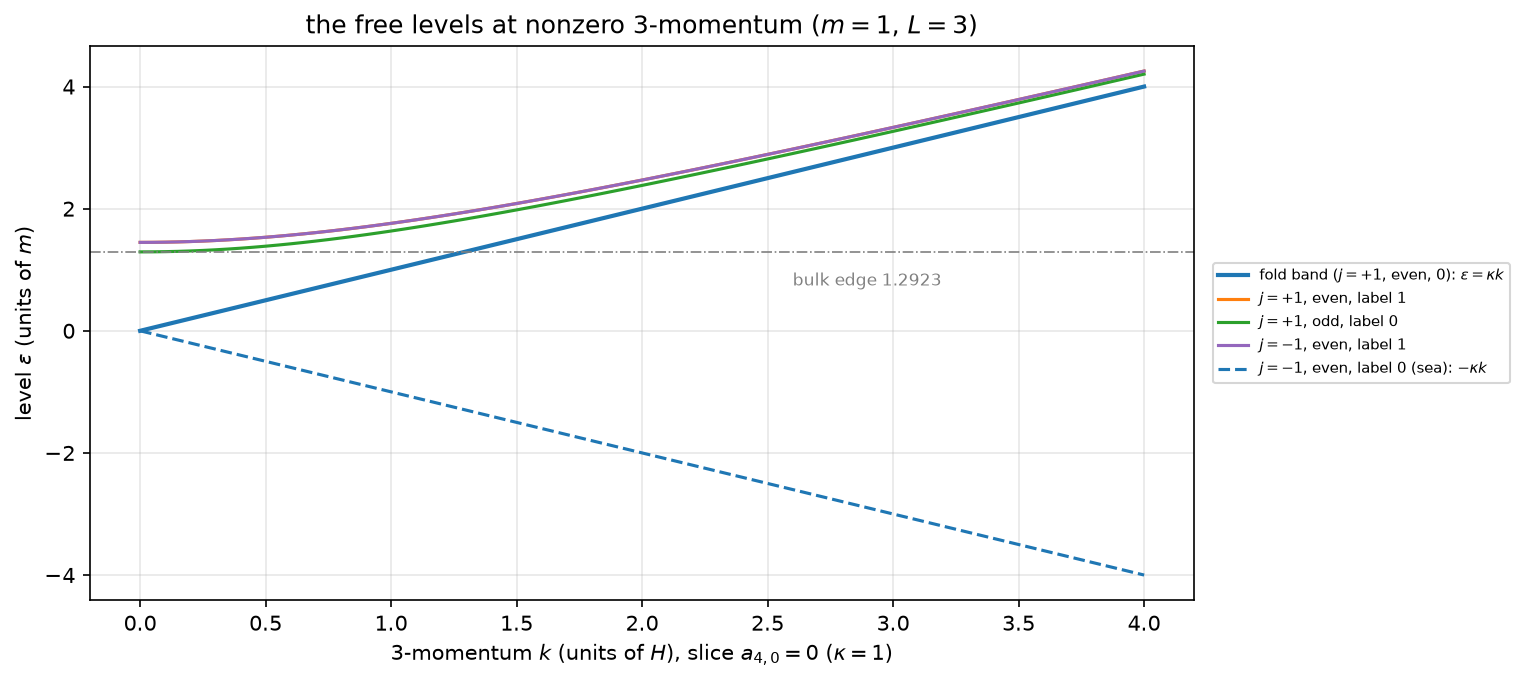

Figure 14c.1 saved as Revision/textbook/figures/14c_1_band_structure.png


In [4]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(k_band, band, color="C0", linewidth=2,
        label="fold band ($j = +1$, even, 0): $\\varepsilon = \\kappa k$")
ax.plot(k_band, bulk_even, color="C1", label="$j = +1$, even, label 1")
ax.plot(k_band, odd0, color="C2", label="$j = +1$, odd, label 0")
ax.plot(k_band, minus_even1, color="C4", label="$j = -1$, even, label 1")
ax.plot(k_band, minus_band, "--", color="C0",
        label="$j = -1$, even, label 0 (sea): $-\\kappa k$")
ax.axhline(odd0[0], color="gray", linewidth=0.8, linestyle="-.")
ax.annotate("bulk edge 1.2923", (2.6, odd0[0] - 0.55), fontsize=8,
            color="gray")  # just below the dash-dotted line
ax.set_xlabel("3-momentum $k$ (units of $H$), slice $a_{4,0} = 0$ ($\\kappa = 1$)")
ax.set_ylabel("level $\\varepsilon$ (units of $m$)")
ax.set_title("the free levels at nonzero 3-momentum ($m = 1$, $L = 3$)")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
save_figure(fig, "band_structure",
            "The free Kohn-Sham levels against the 3-momentum $k$ (units of "
            "$H$) at the slice $a_{4,0} = 0$ for $m = 1$, $L = 3$; vertical axis "
            "the level in units of $m$. The fold band (thick) starts at the zero "
            "mode and is exactly the straight line $\\varepsilon = \\kappa k$ "
            "($\\kappa = 1$ at this slice), with the orbital $(e^{fMy}, 0)$ for "
            "every $k$; the other levels start at or above the bulk edge "
            "$1.2923\\,m$ (dash-dotted) and bend upward along the hyperbolas "
            "$\\varepsilon^2 = \\varepsilon(0)^2 + \\kappa^2k^2$ (the even "
            "levels of label 1 of the two block types are equal, so the purple "
            "curve hides the orange one); the dashed line is the band of the "
            "blocks $j = -1$, the mirror image $-\\kappa k$, which belongs to "
            "the sea.")

## 7. The slope of the band at k = 0: the Hellmann-Feynman rule

Line by line:

1. If $h(k)\chi = \varepsilon(k)\chi$ with $\int\chi^\dagger\chi\,dy = 1$ and
   boundary conditions that do not depend on $k$, then $\varepsilon =
   \int\chi^\dagger h\chi\,dy$, and differentiating, the terms with
   $d\chi/dk$ add up to $\varepsilon\,\frac{d}{dk}\int\chi^\dagger\chi\,dy = 0$
   ($h$ is self-adjoint): $d\varepsilon/dk = \int\chi^\dagger(\partial_k h)\chi
   \,dy$.
2. Here $\partial_k h_j = j\kappa\,\sigma_3$, with $\kappa$ the same at every
   $y$, and at $k = 0$ the orbital is the zero mode $(a, 0)$, so
   $\chi^\dagger\sigma_3\chi = a^2 = \chi^\dagger\chi$.
3. Hence $d\varepsilon/dk = j\kappa\int a^2\,dy = j\kappa$: the slope is
   $c = \kappa = e^{-a_{4,0}}$ for every $M$, $L$ and $f$; at the slice 0 it is
   1. (The exact band of section 6 says the same for every $k$.)

The next cell does step 3 with sympy, compares with the Revision record
(`checksNumeric` of ks-theory.json: 1 at the slice 0 and $e^{-1/2} =
0.6065306597$ at the slice 0.5), and measures the slope numerically at the five
slices as the Rust solver did: levels at $k = 10^{-4}$ and $2\times10^{-4}$, and
the Richardson combination $c = (4\varepsilon_1/10^{-4} -
\varepsilon_2/(2\times10^{-4}))/3$, which removes a $k^2$ error of
$\varepsilon/k$ (here there is none). These must equal the record
`brane-band-slope.csv`. Finally it measures the slope for other masses $M$ and
cutoffs $L$ at two slices: it does not change.

In [5]:
f_p, M_p, L_p = sp.symbols("f M L", positive=True)
s3 = sp.Matrix([[1, 0], [0, -1]])  # sigma3
zero_mode = sp.Matrix([sp.exp(f_p * M_p * ys), 0])  # (a, 0), not yet normalised
expect_s3 = (zero_mode.T * s3 * zero_mode)[0]  # chi^dag sigma3 chi = a^2
norm_sq = (zero_mode.T * zero_mode)[0]  # chi^dag chi = a^2
slope = sp.simplify(kaps * sp.integrate(expect_s3, (ys, -L_p, 0))
                    / sp.integrate(norm_sq, (ys, -L_p, 0)))  # step 3
theory = json.loads(repository_file("Revision/kohn_sham/ks-theory.json")
                    .read_text(encoding="utf-8"))
numbers = theory["checksNumeric"]
report("slope c of the fold band (exact)", f"{slope}")
check(slope == kaps and float(numbers["braneBandSlope_a0"]) == 1.0
      and abs(float(numbers["braneBandSlope_a0_half_history"]) - math.exp(-0.5))
      < 1e-15
      and record_check("brane_band_slope",
                       "Revision/kohn_sham/reports/ks-theory-python.json"),
      "c = kappa = e^(-a4,0) for every M, L, f (1 at the slice 0)",
      record="Revision/kohn_sham/ks-theory.json, checksNumeric braneBandSlope_a0 "
             "and braneBandSlope_a0_half_history")
tiny = np.array([1e-4, 2e-4] * 5)  # two small momenta at each slice
slice_of = np.repeat(SLICES, 2)
small = levels(tiny, 1.0, "even", 0, a4=slice_of).reshape(5, 2)
c_numeric = (4.0 * small[:, 0] / 1e-4 - small[:, 1] / 2e-4) / 3.0
rows = read_csv(f"{SPECTRUM}/brane-band-slope.csv")
c_rows = np.array([float(r["c_numeric"]) for r in rows])
for a_, c_ in zip(SLICES, c_numeric):
    say(f"slice a4,0 = {a_}: c numerical {c_:.15f}, e^(-a4,0) {math.exp(-a_):.15f}")
check(np.max(np.abs(c_numeric / c_rows - 1.0)) < 1e-11
      and np.max(np.abs(c_numeric / np.exp(-np.array(SLICES)) - 1.0)) < 1e-11
      and record_check("free_brane_band_slope"),
      "the numerical slope equals e^(-a4,0) at all five slices",
      record=f"{SPECTRUM}/brane-band-slope.csv and {RUST_REPORT}, check "
             "free_brane_band_slope")
cases = [(M_, L_, a_) for a_ in (0.0, 1.0) for M_, L_ in
         ((0.5, 3.0), (1.0, 1.0), (1.0, 2.0), (1.0, 4.0), (1.0, 6.0), (2.0, 3.0))]
c_cases = []
for M_, L_, a_ in cases:
    pair = levels(np.array([1e-4, 2e-4]), 1.0, "even", 0, a4=a_, M=M_, L=L_,
                  G=round(300 * L_))
    c_cases.append((4.0 * pair[0] / 1e-4 - pair[1] / 2e-4) / 3.0)
worst_case = max(abs(c_ / math.exp(-a_) - 1.0) for c_, (_, _, a_) in
                 zip(c_cases, cases))
say("slopes for (M, L) = (0.5, 3), (1, 1), (1, 2), (1, 4), (1, 6), (2, 3):")
say("  slice 0: " + ", ".join(f"{c_:.12f}" for c_ in c_cases[:6]))
say("  slice 1: " + ", ".join(f"{c_:.12f}" for c_ in c_cases[6:]))
check(worst_case < 1e-11, "the slope is e^(-a4,0) for other masses and cutoffs too")

RESULT slope c of the fold band (exact) = kappa
PASS c = kappa = e^(-a4,0) for every M, L, f (1 at the slice 0)
     reproduces Revision/kohn_sham/ks-theory.json, checksNumeric braneBandSlope_a0 and
    braneBandSlope_a0_half_history
slice a4,0 = 0.0: c numerical 1.000000000000000, e^(-a4,0) 1.000000000000000
slice a4,0 = 0.5: c numerical 0.606530659712633, e^(-a4,0) 0.606530659712633
slice a4,0 = 1.0: c numerical 0.367879441171442, e^(-a4,0) 0.367879441171442
slice a4,0 = 1.5: c numerical 0.223130160148430, e^(-a4,0) 0.223130160148430
slice a4,0 = 2.0: c numerical 0.135335283236613, e^(-a4,0) 0.135335283236613
PASS the numerical slope equals e^(-a4,0) at all five slices
     reproduces Revision/kohn_sham/results/spectrum/brane-band-slope.csv and
    Revision/kohn_sham/reports/ks-rust-solver.json, check free_brane_band_slope
slopes for (M, L) = (0.5, 3), (1, 1), (1, 2), (1, 4), (1, 6), (2, 3):
  slice 0: 1.000000000000, 1.000000000000, 1.000000000000, 1.000000000000,
    1.000000000000

The next cell draws the slope. Left: $c$ at the five slices (numerical points)
on the exact curve $e^{-a_{4,0}}$, logarithmic vertical axis. Right: $c$ for the
six pairs of mass $M$ and cutoff $L$ at the slices 0 and 1: every value equals
$\kappa$.

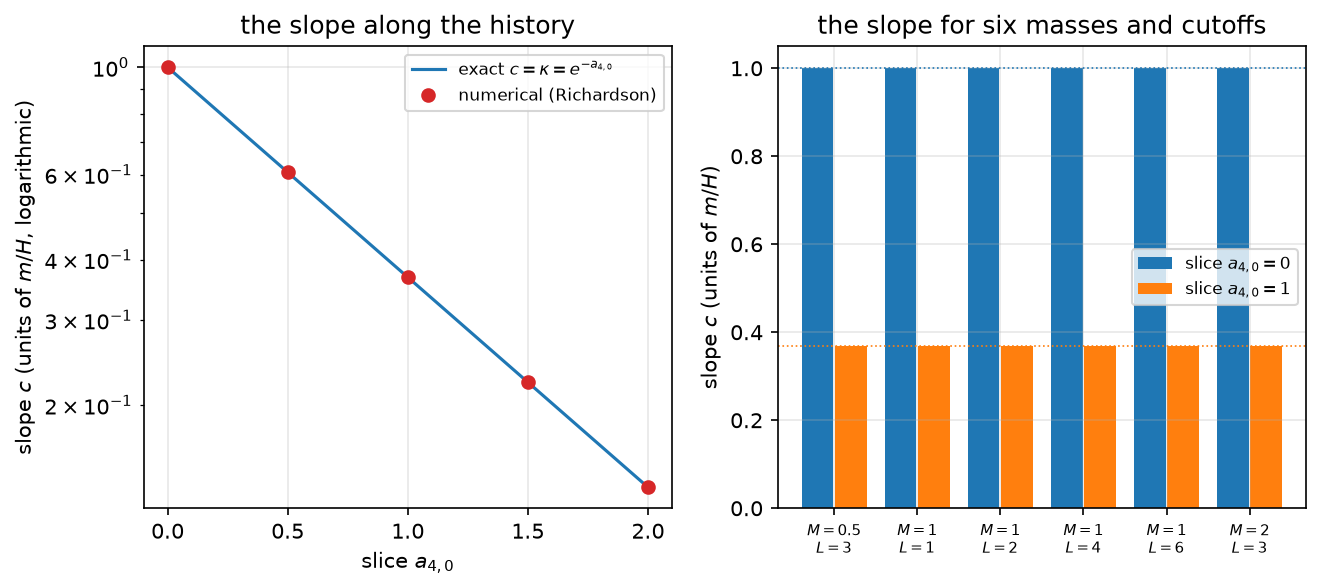

Figure 14c.2 saved as Revision/textbook/figures/14c_2_band_slope.png


In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10.0, 4.0))
a_grid = np.linspace(0.0, 2.0, 201)
left.semilogy(a_grid, np.exp(-a_grid), color="C0",
              label="exact $c = \\kappa = e^{-a_{4,0}}$")
left.semilogy(SLICES, c_numeric, "o", color="C3", label="numerical (Richardson)")
left.set_xlabel("slice $a_{4,0}$")
left.set_ylabel("slope $c$ (units of $m/H$, logarithmic)")
left.set_title("the slope along the history")
left.legend(fontsize=8)
names = [f"$M = {M_:g}$\n$L = {L_:g}$" for M_, L_, _ in cases[:6]]
positions = np.arange(6)
right.bar(positions - 0.2, c_cases[:6], width=0.38, label="slice $a_{4,0} = 0$")
right.bar(positions + 0.2, c_cases[6:], width=0.38, label="slice $a_{4,0} = 1$")
right.axhline(1.0, color="C0", linestyle=":", linewidth=0.8)
right.axhline(math.exp(-1.0), color="C1", linestyle=":", linewidth=0.8)
right.set_xticks(positions)
right.set_xticklabels(names, fontsize=7)
right.set_ylabel("slope $c$ (units of $m/H$)")
right.set_title("the slope for six masses and cutoffs")
right.legend(fontsize=8)
save_figure(fig, "band_slope",
            "The slope $c = d\\varepsilon/dk$ of the fold band at $k = 0$. Left: "
            "against the slice $a_{4,0}$ from 0 to 2, logarithmic vertical axis; "
            "the numerical Richardson values (dots) lie on the exact line "
            "$c = \\kappa = e^{-a_{4,0}}$: the band is redshifted along the "
            "history. Right: the numerical slope for six pairs of mass $M$ and "
            "cutoff $L$ (units of $m$ and $1/H$) at the slices 0 (left bars) and "
            "1 (right bars): every value is $1$ or $e^{-1}$ (dotted lines), "
            "whatever $M$ and $L$, because the band orbital $(e^{fMy}, 0)$ has "
            "$\\chi^\\dagger\\sigma_3\\chi = \\chi^\\dagger\\chi$ and $\\kappa$ is "
            "the same at every $y$.")

## 8. The deflating history: redshift and the exact rescaling relation

By the exact rescaling identity (Notebook 14a) a slice $a_{4,0}$ of the free
problem is the slice 0 with the momentum $k\,e^{-a_{4,0}}$ and the proper cutoff
$f_0L$, $f_0 = e^{-a_{4,0}/3}$ (the constant $H$ does not enter the free levels):
EXACTLY $\varepsilon(k, a_{4,0}; L) = \varepsilon(k\,e^{-a_{4,0}}, 0; f_0L)$ for
every level. The next cell checks this as the Rust solver did (check
`free_rescaling_relation_and_band_monotone`): for $k = 0.25, 1, 2.5$, the five
slices and four sectors, on the same number of RK4 steps, the level at the slice
and the level of the partner agree to $10^{-12}$. It then computes the gap of the
free $N = 8$ state at every slice: the eight zero modes are filled and the next
level is the band at the first lattice shell $k = \Delta k = 0.25$, so the gap is
exactly $\kappa\Delta k = 0.25\,e^{-a_{4,0}}$; it must equal the record
`closed-shells.csv` (rows $N = 8$) and the Kohn-Sham gap of the free ground states
`N8_lam0_a00` to `N8_lam0_a20` of `ground/summary.csv`. Finally, for the
figure, it computes the fold band at the five slices and the two lowest levels
away from the band at $k = 0$ (odd label 0 and even label 1), which RISE along
the history, because the hidden direction shrinks ($fL$ decreases).

In [7]:
test_k = [0.25, 1.0, 2.5]
test_sectors = [(1.0, "even", 0), (1.0, "odd", 0), (-1.0, "even", 1),
                (1.0, "even", 1)]
worst_partner = 0.0
for a_ in SLICES:
    combos = [(k_, s_) for k_ in test_k for s_ in test_sectors]
    args = (np.array([s_[0] for _, s_ in combos]), np.array([s_[1] for _, s_ in combos]),
            np.array([s_[2] for _, s_ in combos]))
    at_slice = levels(np.array([k_ for k_, _ in combos]), *args, a4=a_)
    partner = levels(np.array([k_ * math.exp(-a_) for k_, _ in combos]), *args,
                     a4=0.0, L=float(hidden_scale(a_)) * 3.0, G=900)
    worst_partner = max(worst_partner, float(np.max(np.abs(at_slice - partner))))
report("largest difference between a slice and its partner", f"{worst_partner:.1e}",
       "m")
gaps = levels(np.full(5, 0.25), 1.0, "even", 0, a4=np.array(SLICES))
shells_record = read_csv(f"{SPECTRUM}/closed-shells.csv")
gap_record = [float(r["gap"]) for r in shells_record if r["N_closed"] == "8"]
summary = read_csv("Revision/kohn_sham/results/ground/summary.csv")
gap_summary = [float(r["KS_gap"]) for r in summary if r["id"].startswith("N8_lam0_")]
for a_, g_ in zip(SLICES, gaps):
    say(f"slice a4,0 = {a_}: gap of the free N = 8 state {g_:.13f} m, "
        f"0.25 e^(-a4,0) = {0.25 * math.exp(-a_):.13f}")
check(worst_partner < 1e-12 and len(gap_record) == 5 and len(gap_summary) == 5
      and np.max(np.abs(gaps - np.array(gap_record))) < 1e-13
      and np.max(np.abs(gaps - np.array(gap_summary))) < 1e-13
      and np.max(np.abs(gaps - 0.25 * np.exp(-np.array(SLICES)))) < 1e-15,
      "eps(k, a4,0; L) = eps(k e^(-a4,0), 0; f0 L); the N = 8 gap is 0.25 e^(-a4,0)",
      record=f"{SPECTRUM}/closed-shells.csv (N_closed = 8) and "
             "Revision/kohn_sham/results/ground/summary.csv, KS_gap of N8_lam0")
k_fig = np.linspace(0.0, 2.0, 21)
band_slices = levels(np.tile(k_fig, 5), 1.0, "even", 0,
                     a4=np.repeat(SLICES, len(k_fig))).reshape(5, len(k_fig))
a_dense = np.linspace(0.0, 2.0, 21)
edge_odd = levels(np.zeros(21), 1.0, "odd", 0, a4=a_dense)  # bulk levels at k = 0
edge_even = levels(np.zeros(21), 1.0, "even", 1, a4=a_dense)
say(f"lowest odd level at k = 0: {edge_odd[0]:.6f} m at a4,0 = 0, "
    f"{edge_odd[-1]:.6f} m at a4,0 = 2")

RESULT largest difference between a slice and its partner = 8.9e-16 m
slice a4,0 = 0.0: gap of the free N = 8 state 0.2500000000000 m, 0.25 e^(-a4,0) =
    0.2500000000000
slice a4,0 = 0.5: gap of the free N = 8 state 0.1516326649282 m, 0.25 e^(-a4,0) =
    0.1516326649282
slice a4,0 = 1.0: gap of the free N = 8 state 0.0919698602929 m, 0.25 e^(-a4,0) =
    0.0919698602929
slice a4,0 = 1.5: gap of the free N = 8 state 0.0557825400371 m, 0.25 e^(-a4,0) =
    0.0557825400371
slice a4,0 = 2.0: gap of the free N = 8 state 0.0338338208092 m, 0.25 e^(-a4,0) =
    0.0338338208092
PASS eps(k, a4,0; L) = eps(k e^(-a4,0), 0; f0 L); the N = 8 gap is 0.25 e^(-a4,0)
     reproduces Revision/kohn_sham/results/spectrum/closed-shells.csv (N_closed = 8) and
    Revision/kohn_sham/results/ground/summary.csv, KS_gap of N8_lam0
lowest odd level at k = 0: 1.292293 m at a4,0 = 0, 1.735554 m at a4,0 = 2


The next cell draws the redshift. Left: the fold band against $k$ at the five
slices: straight lines with the slopes $e^{-a_{4,0}}$. Right: against the slice,
the gap of the eight zero modes $\kappa\Delta k$ (it falls like $e^{-a_{4,0}}$),
and the two lowest levels away from the band at $k = 0$, which rise (logarithmic
vertical axis).

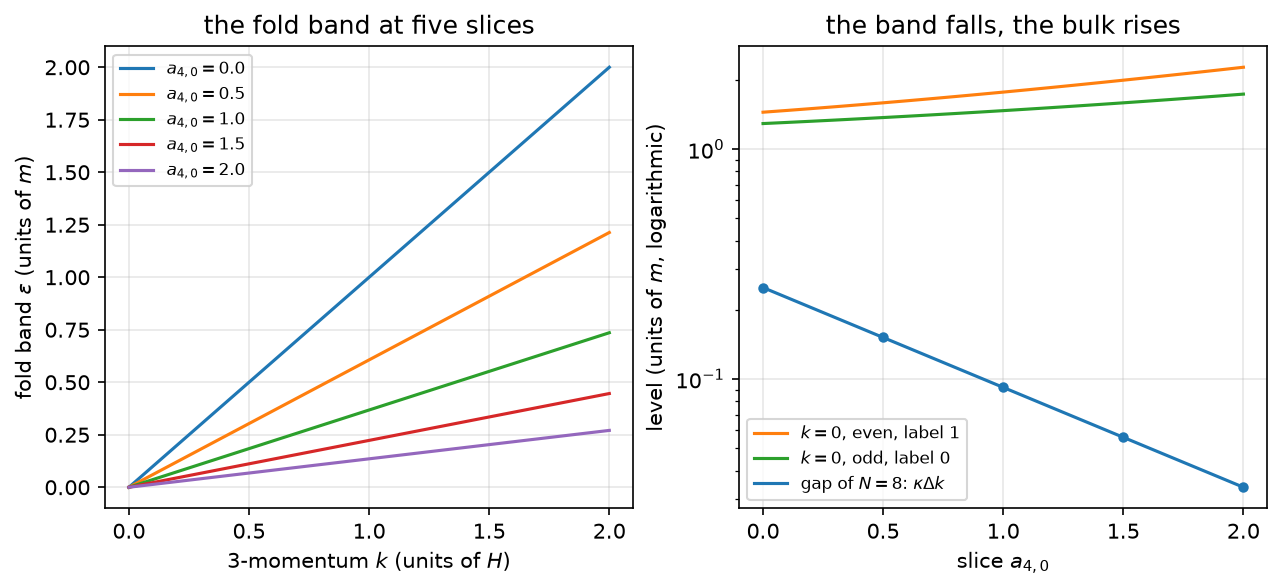

Figure 14c.3 saved as Revision/textbook/figures/14c_3_band_redshift.png


In [8]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10.0, 4.0))
for index, a_ in enumerate(SLICES):
    left.plot(k_fig, band_slices[index], label=f"$a_{{4,0}} = {a_}$")
left.set_xlabel("3-momentum $k$ (units of $H$)")
left.set_ylabel("fold band $\\varepsilon$ (units of $m$)")
left.set_title("the fold band at five slices")
left.legend(fontsize=8)
right.semilogy(a_dense, edge_even, color="C1", label="$k = 0$, even, label 1")
right.semilogy(a_dense, edge_odd, color="C2", label="$k = 0$, odd, label 0")
right.semilogy(a_grid, 0.25 * np.exp(-a_grid), color="C0",
               label="gap of $N = 8$: $\\kappa \\Delta k$")
right.semilogy(SLICES, gaps, "o", color="C0", markersize=4)
right.set_xlabel("slice $a_{4,0}$")
right.set_ylabel("level (units of $m$, logarithmic)")
right.set_title("the band falls, the bulk rises")
right.legend(fontsize=8)
save_figure(fig, "band_redshift",
            "The fold band along the prescribed deflating history. Left: the band "
            "$\\varepsilon = \\kappa k$ (units of $m$) against the 3-momentum $k$ "
            "(units of $H$) at the five slices $a_{4,0} = 0$ to $2$: straight "
            "lines with the slopes $e^{-a_{4,0}}$, later slices lower. Right, "
            "against the slice on a logarithmic vertical axis: the gap of the "
            "eight zero modes, the band level at the first lattice shell "
            "$\\kappa\\Delta k = 0.25e^{-a_{4,0}}$ (line; dots at the five slices "
            "of the record), and the two lowest levels away from the band at "
            "$k = 0$ (odd label 0, even label 1), which rise along the history "
            "because the proper length $fL = 3e^{-a_{4,0}/3}$ of the cut-off half "
            "shrinks.")

## 9. The mirror symmetries of the two block types

Two exact relations of the block Hamiltonian (for $v = 0$): $h_{-1} = -h_{+1}$,
so the levels of $j = -1$ are the negatives of those of $j = +1$, with the
labels $l \to -l$ (even) and $l \to -l - 1$ (odd); and $\sigma_3h_j(k)\sigma_3 =
h_{-j}(-k)$, so the level of $(j = -1, -k)$ with label $l$ equals the level of
$(j = +1, k)$ with the same label. The next cell checks both for the shells
$n^2 = 0, 1, 2, 5, 9$ ($k = 0.25\sqrt{n^2}$) and the labels $-3$ to $3$ of both
fold conditions at the slice 0 (the Rust check `free_block_type_symmetries`), and
computes the even levels of both block types for $k$ from 0 to 2 for the figure.

In [9]:
sym_k = [0.25 * math.sqrt(n2) for n2 in (0, 1, 2, 5, 9)]
sym_l = list(range(-3, 4))
grid = [(k_, l_) for k_ in sym_k for l_ in sym_l]
K_s = np.array([k_ for k_, l_ in grid])
L_s = np.array([l_ for k_, l_ in grid])
plus_even = levels(K_s, 1.0, "even", L_s)
minus_even = levels(K_s, -1.0, "even", -L_s)
plus_odd = levels(K_s, 1.0, "odd", L_s)
minus_odd = levels(K_s, -1.0, "odd", -L_s - 1)
flipped_even = levels(-K_s, -1.0, "even", L_s)
flipped_odd = levels(-K_s, -1.0, "odd", L_s)
mirror = max(np.max(np.abs(plus_even + minus_even)),
             np.max(np.abs(plus_odd + minus_odd)))
flip = max(np.max(np.abs(flipped_even - plus_even)),
           np.max(np.abs(flipped_odd - plus_odd)))
check(mirror < 1e-12 and flip < 1e-12 and record_check("free_block_type_symmetries"),
      "spec h_(-1) = -spec h_(+1) and eps_(-1)(-k) = eps_(+1)(k), label by label",
      record=f"{RUST_REPORT}, check free_block_type_symmetries")
k_mirror = np.linspace(0.0, 2.0, 41)
fig_labels = list(range(-2, 3))
plus_curves = levels(np.tile(k_mirror, 5), 1.0, "even",
                     np.repeat(fig_labels, len(k_mirror))).reshape(5, -1)
minus_curves = levels(np.tile(k_mirror, 5), -1.0, "even",
                      np.repeat(fig_labels, len(k_mirror))).reshape(5, -1)
say("even levels at k = 2, labels -2 ... 2:")
say("  j = +1: " + ", ".join(f"{x:.4f}" for x in plus_curves[:, -1]))
say("  j = -1: " + ", ".join(f"{x:.4f}" for x in minus_curves[:, -1]))

PASS spec h_(-1) = -spec h_(+1) and eps_(-1)(-k) = eps_(+1)(k), label by label
     reproduces Revision/kohn_sham/reports/ks-rust-solver.json, check
    free_block_type_symmetries
even levels at k = 2, labels -2 ... 2:
  j = +1: -3.0637, -2.4691, 2.0000, 2.4691, 3.0637
  j = -1: -3.0637, -2.4691, -2.0000, 2.4691, 3.0637


The next cell draws the even levels of the two block types against $k$: the
picture of $j = -1$ is the picture of $j = +1$ turned upside down.

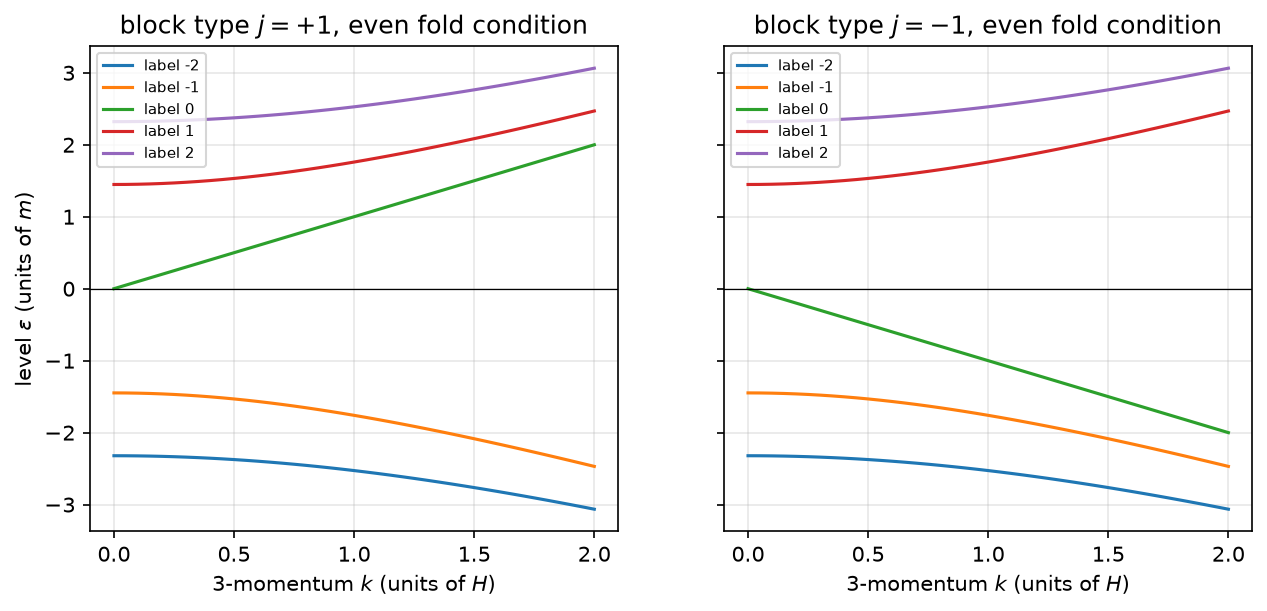

Figure 14c.4 saved as Revision/textbook/figures/14c_4_block_type_mirror.png


In [10]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10.0, 4.2), sharey=True)
for row, label in enumerate(fig_labels):
    left.plot(k_mirror, plus_curves[row], label=f"label {label}")
    right.plot(k_mirror, minus_curves[row], label=f"label {label}")
for ax, title in ((left, "block type $j = +1$"), (right, "block type $j = -1$")):
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.set_xlabel("3-momentum $k$ (units of $H$)")
    ax.set_title(title + ", even fold condition")
    ax.legend(fontsize=7, loc="upper left")
left.set_ylabel("level $\\varepsilon$ (units of $m$)")
save_figure(fig, "block_type_mirror",
            "The levels of the even fold condition with labels $-2$ to $2$ against "
            "the 3-momentum $k$ (units of $H$), slice 0, $m = 1$, $L = 3$; "
            "vertical axis the level in units of $m$. Left the blocks $j = +1$, "
            "right the blocks $j = -1$: each picture is the other one reflected in "
            "the line $\\varepsilon = 0$ (label $l$ goes to $-l$), the exact "
            "relation $h_{-1} = -h_{+1}$; the rising straight line of the label 0 "
            "on the left is the fold band $\\varepsilon = \\kappa k$, the falling "
            "one on the right its sea partner.")

## 10. The tip angle

The cutoff $y = -L$ is a choice of the numerical model, and so is the tip
condition $(1 - Q(\theta))\chi(-L) = 0$, canonical $\theta = 0$. How much does the
choice of $\theta$ matter? An exact identity answers it. Take the orbital
$\chi_0$ of a level with $\theta = 0$ and the orbital $\chi_\theta$ of the same
label with the tip angle $\theta$ (same $k$, $j$ and fold condition). Integrating
$\varphi^\dagger h_j\chi - (h_j\varphi)^\dagger\chi = \frac{d}{dy}[-(ij/f)
\varphi^\dagger\sigma_1\chi]$ from $-L$ to $0$, with both orbitals obeying the
same fold condition (so the end term at $y = 0$ vanishes) and $b_0(-L) = 0$:

$$(\varepsilon_\theta - \varepsilon_0)\int_{-L}^0\chi_0^\dagger\chi_\theta\,dy =
-\frac{j}{f}\,a_0(-L)\,b_\theta(-L) .$$

The shift of a level is therefore set by the size of its orbital at the tip. For
the fold band, $a_0(-L)^2 = 2fMe^{-2fML}/(1 - e^{-2fML})$ is small (its tail at the
tip), and to first order the shift is about $\tan(\theta/2)\,a_0(-L)^2/f$.
Nothing suppresses an extended orbital toward the tip ($\kappa$ does not depend on
$y$; Notebook 14b), so the levels away from the band move a lot. The next cell
computes the fold band (label 0) and the next even level (label 1) for $\theta =
0, 0.5, 1$, $k = 0.25, 0.5, 1$ at the slices 0 and 1.5 (the record
`tip-angle.csv`), checks the levels and the identity, and reports the largest
band shift, its largest ratio to the first-order estimate and the smallest shift
of the extended level (the Rust check `free_tip_angle_boundary_identity`). Then it
computes the shifts at $k = 0.25$ for tip angles from 0.1 to 1.5 for the figure.

In [11]:
tip_rows = read_csv(f"{SPECTRUM}/tip-angle.csv")
rows_a = np.array([float(r["a4"]) for r in tip_rows])  # the 24 cases of the record
rows_k = np.array([float(r["k"]) for r in tip_rows])
rows_l = np.array([int(r["label"]) for r in tip_rows])
rows_t = np.array([float(r["theta_tip"]) for r in tip_rows])
e0_all = levels(rows_k, 1.0, "even", rows_l, a4=rows_a)  # tip angle 0
eth_all = levels(rows_k, 1.0, "even", rows_l, a4=rows_a, tip=rows_t)  # angle theta
worst_level, worst_identity = 0.0, 0.0
band_shift, ratio_max, bulk_shift = 0.0, 0.0, float("inf")
for r, a_, k_, label, th, e0, e_th in zip(tip_rows, rows_a, rows_k, rows_l, rows_t,
                                           e0_all, eth_all):
    f_ = float(hidden_scale(a_))
    _, a0_, b0_, w_ = orbital(float(e0), k_, 1.0, a_)
    _, at_, bt_, _ = orbital(float(e_th), k_, 1.0, a_, tip=th)
    overlap = float(np.sum(w_ * (a0_ * at_ + b0_ * bt_)))
    boundary = -a0_[0] * bt_[0] / f_  # -j a_0(-L) b_theta(-L)/f with j = +1
    worst_identity = max(worst_identity, abs((e_th - e0) * overlap - boundary))
    worst_level = max(worst_level, abs(e_th - float(r["eps"])))
    tail = 2.0 * f_ * math.exp(-6.0 * f_) / (1.0 - math.exp(-6.0 * f_))  # a_0(-L)^2
    if label == 0:
        band_shift = max(band_shift, abs(e_th - e0))
        ratio_max = max(ratio_max, abs(e_th - e0) / (math.tan(0.5 * th) * tail / f_))
    else:
        bulk_shift = min(bulk_shift, abs(e_th - e0))
report("largest shift of the fold band", f"{band_shift:.2e}", "m")
report("largest ratio to the first-order estimate", f"{ratio_max:.3f}")
report("smallest shift of the extended level (label 1)", f"{bulk_shift:.3e}", "m")
report("largest residual of the boundary identity", f"{worst_identity:.1e}")
check(len(tip_rows) == 24 and worst_level < 1e-11 and worst_identity < 1e-9
      and record_check("free_tip_angle_boundary_identity"),
      "the 24 levels equal tip-angle.csv and obey the exact boundary identity",
      record=f"{SPECTRUM}/tip-angle.csv and {RUST_REPORT}, check "
             "free_tip_angle_boundary_identity")
import re  # regular expressions: patterns that find numbers in a text

detail = [c["detail"] for c in json.loads(repository_file(RUST_REPORT).read_text(
    encoding="utf-8"))["checks"] if c["name"] == "free_tip_angle_boundary_identity"][0]
rec_band = re.search(r"shifts by at most (\S+),", detail).group(1)
rec_ratio = re.search(r"at most (\S+) times", detail).group(1)
rec_bulk = re.search(r"shifts by at least (\S+):", detail).group(1)
check(f"{band_shift:.2e}" == f"{float(rec_band):.2e}" and f"{ratio_max:.3f}" == rec_ratio
      and f"{bulk_shift:.3e}" == f"{float(rec_bulk):.3e}",
      f"band shift at most {band_shift:.2e}, extended level at least {bulk_shift:.3e}",
      record=f"{RUST_REPORT}, check free_tip_angle_boundary_identity (detail)")
thetas = np.linspace(0.1, 1.5, 15)
shift_curves = {}
for a_ in (0.0, 1.5):
    for label in (0, 1):
        reference = float(levels(0.25, 1.0, "even", label, a4=a_))
        shift_curves[(a_, label)] = np.abs(
            levels(0.25, 1.0, "even", label, a4=a_, tip=thetas) - reference)

RESULT largest shift of the fold band = 3.26e-02 m
RESULT largest ratio to the first-order estimate = 2.127
RESULT smallest shift of the extended level (label 1) = 6.157e-02 m
RESULT largest residual of the boundary identity = 1.1e-12
PASS the 24 levels equal tip-angle.csv and obey the exact boundary identity
     reproduces Revision/kohn_sham/results/spectrum/tip-angle.csv and
    Revision/kohn_sham/reports/ks-rust-solver.json, check
    free_tip_angle_boundary_identity
PASS band shift at most 3.26e-02, extended level at least 6.157e-02
     reproduces Revision/kohn_sham/reports/ks-rust-solver.json, check
    free_tip_angle_boundary_identity (detail)


The next cell prints the smallest and the largest of these shifts and draws the
shifts $|\varepsilon_\theta - \varepsilon_0|$ at $k = 0.25$ against the tip
angle, for the fold band (label 0) and the extended level (label 1) at the
slices 0 and 1.5, on a logarithmic axis, together with the first-order estimate
$\tan(\theta/2)\,a_0(-L)^2/f$ of the band shift.

slice 0.0, label 0: shift 2.52e-04 m at theta = 0.1, 5.97e-03 m at theta = 1.5
slice 0.0, label 1: shift 1.05e-02 m at theta = 0.1, 3.25e-01 m at theta = 1.5
slice 1.5, label 0: shift 2.71e-03 m at theta = 0.1, 5.15e-02 m at theta = 1.5
slice 1.5, label 1: shift 2.16e-02 m at theta = 0.1, 4.97e-01 m at theta = 1.5


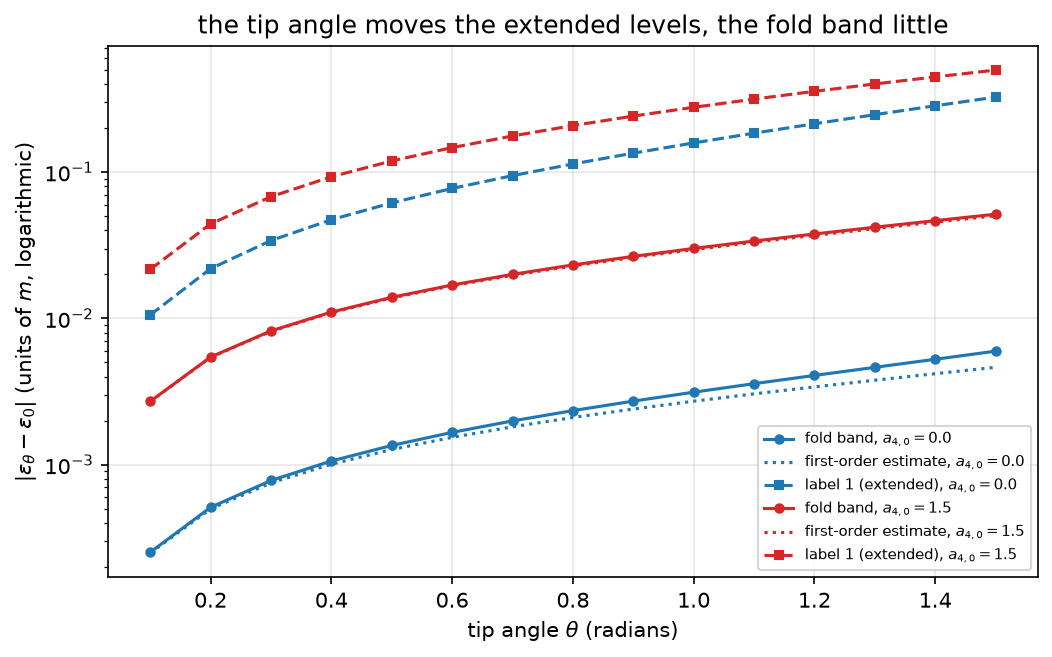

Figure 14c.5 saved as Revision/textbook/figures/14c_5_tip_angle.png


In [12]:
for (a_, label), values in shift_curves.items():
    say(f"slice {a_}, label {label}: shift {values[0]:.2e} m at theta = 0.1, "
        f"{values[-1]:.2e} m at theta = 1.5")
fig, ax = plt.subplots(figsize=(8.0, 4.6))
for a_, color in ((0.0, "C0"), (1.5, "C3")):
    f_ = float(hidden_scale(a_))
    tail = 2.0 * f_ * math.exp(-6.0 * f_) / (1.0 - math.exp(-6.0 * f_))
    ax.semilogy(thetas, shift_curves[(a_, 0)], "o-", color=color, markersize=4,
                label=f"fold band, $a_{{4,0}} = {a_}$")
    ax.semilogy(thetas, np.tan(0.5 * thetas) * tail / f_, ":", color=color,
                label=f"first-order estimate, $a_{{4,0}} = {a_}$")
    ax.semilogy(thetas, shift_curves[(a_, 1)], "s--", color=color, markersize=4,
                label=f"label 1 (extended), $a_{{4,0}} = {a_}$")
ax.set_xlabel("tip angle $\\theta$ (radians)")
ax.set_ylabel("$|\\varepsilon_\\theta - \\varepsilon_0|$ (units of $m$, logarithmic)")
ax.set_title("the tip angle moves the extended levels, the fold band little")
ax.legend(fontsize=7, loc="lower right")
save_figure(fig, "tip_angle",
            "The change of two levels at the 3-momentum $k = 0.25$ when the tip "
            "condition $(1 - Q(\\theta))\\chi(-L) = 0$ is changed from "
            "$\\theta = 0$ to $\\theta$ (horizontal axis, radians), for $m = 1$, "
            "$L = 3$, at the slices $a_{4,0} = 0$ (blue) and $1.5$ (red), "
            "logarithmic vertical axis in units of $m$. Circles: the fold band "
            "(label 0), whose orbital has only the small tail "
            "$a_0(-L)^2 = 2fMe^{-2fML}/(1 - e^{-2fML})$ at the tip; dotted: the "
            "first-order estimate $\\tan(\\theta/2)a_0(-L)^2/f$ of its shift. "
            "Squares: the extended level of label 1, which nothing suppresses "
            "toward the tip: it moves by about $0.01$ to $0.33\\,m$ at the slice 0 "
            "and $0.02$ to $0.50\\,m$ at the slice 1.5, the band by about "
            "$0.0003$ to $0.006\\,m$ and $0.003$ to $0.05\\,m$. At the later "
            "slice the hidden direction is shorter ($f = e^{-1/2}$), the tail is "
            "larger and the band shifts more.")

## 11. Particles, degeneracies and closed shells

**Shells.** The lattice vectors $(n_1, n_2, n_3)$ with the same
$n^2 = n_1^2 + n_2^2 + n_3^2$ have the same $|k| = 0.25\sqrt{n^2}$; $r_3(n^2)$
counts them (the first values are $r_3 = 1, 6, 12, 8, 6, 24, 24, 12, 30$ for
$n^2 = 0, 1, 2, 3, 4, 5, 6, 8, 9$; no vector has $n^2 = 7$). Each level of a
block type then holds $4r_3(n^2)$ states.

**Particles (CONVENTION).** In each sector (shell, $j$, fold condition) the
particle levels are those with $\varepsilon > 0$ in the free problem, plus the
$k = 0$ zero modes; the negative ones form the sea. Because $\Phi$ grows with
$\varepsilon$, the particle levels are exactly the labels $l \ge l_{\min}$, where
$l_{\min}$ is the first label whose target lies above $\Phi(0)$. The Rust check
`free_particle_branch_labels` verified this for all shells $n^2 \le 30$ and
found the level closest to zero (away from the zero modes) at $0.2500\,m$, the
fold band at the first shell. The next cell repeats both.

In [13]:
def shells(n2_max):
    """[(n2, r3)] for n2 = 0 ... n2_max with r3(n2) > 0 (counting lattice points)."""
    r = math.isqrt(n2_max) + 1
    count = [0] * (n2_max + 1)
    for x in range(-r, r + 1):
        for y_ in range(-r, r + 1):
            for z_ in range(-r, r + 1):
                s = x * x + y_ * y_ + z_ * z_
                if s <= n2_max:
                    count[s] += 1
    return [(n2, c) for n2, c in enumerate(count) if c > 0]


check(shells(9) == [(0, 1), (1, 6), (2, 12), (3, 8), (4, 6), (5, 24), (6, 24),
                    (8, 12), (9, 30)],
      "r3(n2) = 1, 6, 12, 8, 6, 24, 24, 12, 30 for n2 = 0, 1, 2, 3, 4, 5, 6, 8, 9")
SECTORS = [(1, "even"), (1, "odd"), (-1, "even"), (-1, "odd")]
SIGN = {1: "+1", -1: "-1"}


def lowest_particle_labels(pairs, a4):
    """l_min of each (n2, r3, j, parity) and Phi(0)."""
    k_ = np.array([0.25 * math.sqrt(n2) for n2, _, _, _ in pairs])
    j_ = np.array([float(j) for _, _, j, _ in pairs])
    par = np.array([p for _, _, _, p in pairs])
    phi0 = shoot(0.0, k_, j_, a4)
    offset = np.where(par == "even", 0.0, 0.5 * np.pi)
    l_min = np.floor((phi0 - offset) / np.pi).astype(int) + 1
    nearest = np.round((phi0 - offset) / np.pi).astype(int)
    zero_mode = (k_ == 0.0) & (np.abs(phi0 - offset - nearest * np.pi) < 1e-12)
    return np.where(zero_mode, nearest, l_min), phi0, offset, k_, j_, par


pairs30 = [(n2, r3, j, p) for n2, r3 in shells(30) for j, p in SECTORS]
l_min, phi0, offset, k30, j30, p30 = lowest_particle_labels(pairs30, 0.0)
e_first = levels(k30, j30, p30, l_min)
e_below = levels(k30, j30, p30, l_min - 1)
zero_k = k30 == 0.0
branch_ok = (np.all(e_below < 0.0)
             and np.all(e_first[zero_k & (p30 == "even")] == 0.0)
             and np.all(e_first[~(zero_k & (p30 == "even"))] > 0.0))
closest = float(min(np.min(e_first[~(zero_k & (p30 == "even"))]),
                    np.min(-e_below)))
report("level closest to zero away from the zero modes (n2 <= 30)",
       f"{closest:.4f}", "m")
check(branch_ok and f"{closest:.4f}" == "0.2500"
      and record_check("free_particle_branch_labels"),
      "particles are the labels l >= l_min in every sector (n2 <= 30)",
      record=f"{RUST_REPORT}, check free_particle_branch_labels")

PASS r3(n2) = 1, 6, 12, 8, 6, 24, 24, 12, 30 for n2 = 0, 1, 2, 3, 4, 5, 6, 8, 9
RESULT level closest to zero away from the zero modes (n2 <= 30) = 0.2500 m
PASS particles are the labels l >= l_min in every sector (n2 <= 30)
     reproduces Revision/kohn_sham/reports/ks-rust-solver.json, check
    free_particle_branch_labels


**Closed shells.** Filling the particle states from the bottom (the aufbau),
$N$ is a closed shell when it ends exactly at the end of a group of degenerate
levels (equal within $10^{-9}$). The Rust solver listed them up to
$\varepsilon = 1.6\,m$ at every slice (`closed-shells.csv`), and chose its
particle numbers by a rule: $N = 8$ (the zero modes), $N_{\rm large}$ = the
largest closed shell of the slice 0 whose last filled level lies below the BULK
EDGE (the lowest level not on the fold band, the smaller of the odd label 0 and
the even label 1 at $k = 0$), and $N_{\rm mid}$ = the closed shell nearest to
$N_{\rm large}/4$ (`parameters.json`). The next cell builds the closed shells at
the slices 0 and 0.5 as the Rust solver does: for every shell (in the order of
$n^2$) and sector it finds the particle levels $l_{\min}, l_{\min} + 1, \dots$ up
to $1.6\,m$; it stops at the first shell $n^2 > 0$ that has no level below
$1.6\,m$; it sorts all levels by energy (and by name), groups levels that agree
within $10^{-9}$, and adds up the degeneracies $4r_3(n^2)$. Each level is named
`n2:j:parity:label`. The table must equal the record row by row: the numbers $N$,
the energies to $10^{-11}$, and the names of the last group as a set (the order
of two names inside one group of exactly degenerate levels, such as
`1:+1:odd:0` and `1:-1:odd:0`, follows the last bits of their two computed
energies, which differ between this notebook and the Rust solver). Then it finds
the bulk edge and the particle numbers and compares them with `parameters.json`.
It takes about 40 seconds.

In [14]:
def closed_shells(a4, n2_max, e_max=1.6):
    """[(N, eps_last, eps_next, names)] of the free aufbau at the slice a4."""
    pairs = [(n2, r3, j, p) for n2, r3 in shells(n2_max) for j, p in SECTORS]
    l_next, _, _, k_, j_, par = lowest_particle_labels(pairs, a4)
    found_levels = []  # (energy, degeneracy, name, n2)
    active = np.arange(len(pairs))
    while len(active) > 0:  # one more label in every sector that is still open
        e_ = levels(k_[active], j_[active], par[active], l_next[active], a4=a4)
        keep = e_ <= e_max
        for index, energy in zip(active[keep], e_[keep]):
            n2, r3, j, p = pairs[index]
            found_levels.append((float(energy), 4.0 * r3,
                                 f"{n2}:{SIGN[j]}:{p}:{l_next[index]}", n2))
        active = active[keep]
        l_next[active] += 1
    with_levels = {n2 for _, _, _, n2 in found_levels}
    stop = next(n2 for n2, _ in shells(n2_max) if n2 > 0 and n2 not in with_levels)
    found_levels = [lev for lev in found_levels if lev[3] < stop]
    found_levels.sort(key=lambda lev: (lev[0], lev[2]))
    table, total, i = [], 0.0, 0
    while i < len(found_levels):  # group the degenerate levels
        e0, group, names = found_levels[i][0], 0.0, []
        while i < len(found_levels) and found_levels[i][0] - e0 <= 1e-9:
            group += found_levels[i][1]
            names.append(found_levels[i][2])
            i += 1
        total += group
        following = found_levels[i][0] if i < len(found_levels) else float("nan")
        table.append((int(total), e0, following, ";".join(names)))
    return table, stop


agree = True
tables = {}
for a_, n2_max in ((0.0, 50), (0.5, 120)):
    table, stop = closed_shells(a_, n2_max)
    tables[a_] = table
    mine_rows = [r for r in shells_record if float(r["a4"]) == a_]
    same = len(table) == len(mine_rows) and all(
        int(r["N_closed"]) == t[0] and abs(float(r["eps_last_filled"]) - t[1]) < 1e-11
        and sorted(r["levels_of_the_last_group"].split(";")) == sorted(t[3].split(";"))
        for r, t in zip(mine_rows, table))  # a group is compared as a set of names
    agree &= same and stop < n2_max
    say(f"slice {a_}: {len(table)} closed shells up to 1.6 m, the first shell "
        f"without a level below 1.6 m is n2 = {stop}; equal to the record: {same}")
check(agree, "the closed shells of the slices 0 and 0.5 equal the record row by row",
      record=f"{SPECTRUM}/closed-shells.csv, rows a4 = 0 and 0.5")
say("slice 0, the first closed shells: N = "
    + ", ".join(str(t[0]) for t in tables[0.0][:24]) + ", ...")
bulk_edge = float(min(levels(0.0, 1.0, "odd", 0), levels(0.0, 1.0, "even", 1)))
below_edge = [t for t in tables[0.0] if t[1] < bulk_edge and t[2] - t[1] > 1e-6]
N_large = below_edge[-1][0]
N_mid = min((t[0] for t in below_edge if t[0] >= 8),
            key=lambda n: abs(n - N_large / 4))
parameters = json.loads(repository_file("Revision/kohn_sham/results/parameters.json")
                        .read_text(encoding="utf-8"))
numbers = parameters["particleNumbers"]
report("bulk edge", f"{bulk_edge:.12f}", "m")
report("particle numbers N", f"8, {N_mid}, {N_large}")
check(abs(bulk_edge - numbers["bulkEdge"]) < 1e-12 and N_large == 2352
      and N_mid == 592 and numbers["values"] == [8.0, 592.0, 2352.0],
      "the bulk edge 1.2922928281 and the particle numbers 8, 592, 2352",
      record="Revision/kohn_sham/results/parameters.json, particleNumbers")

slice 0.0: 56 closed shells up to 1.6 m, the first shell without a level below 1.6 m is
    n2 = 41; equal to the record: True
slice 0.5: 123 closed shells up to 1.6 m, the first shell without a level below 1.6 m is
    n2 = 113; equal to the record: True
PASS the closed shells of the slices 0 and 0.5 equal the record row by row
     reproduces Revision/kohn_sham/results/spectrum/closed-shells.csv, rows a4 = 0 and
    0.5
slice 0, the first closed shells: N = 8, 32, 80, 112, 136, 232, 328, 376, 496, 592, 688,
    720, 816, 1008, 1032, 1224, 1368, 1464, 1560, 1752, 1848, 1944, 2064, 2352, ...
RESULT bulk edge = 1.292292828069 m
RESULT particle numbers N = 8, 592, 2352
PASS the bulk edge 1.2922928281 and the particle numbers 8, 592, 2352
     reproduces Revision/kohn_sham/results/parameters.json, particleNumbers


The next cell draws the aufbau as a staircase: the number $N$ of filled
particle states against the energy of the last filled level, at the slices 0 and
0.5, with the bulk edge and the three particle numbers of the Revision runs
marked. At the later slice the redshifted band holds many more states below the
same energy.

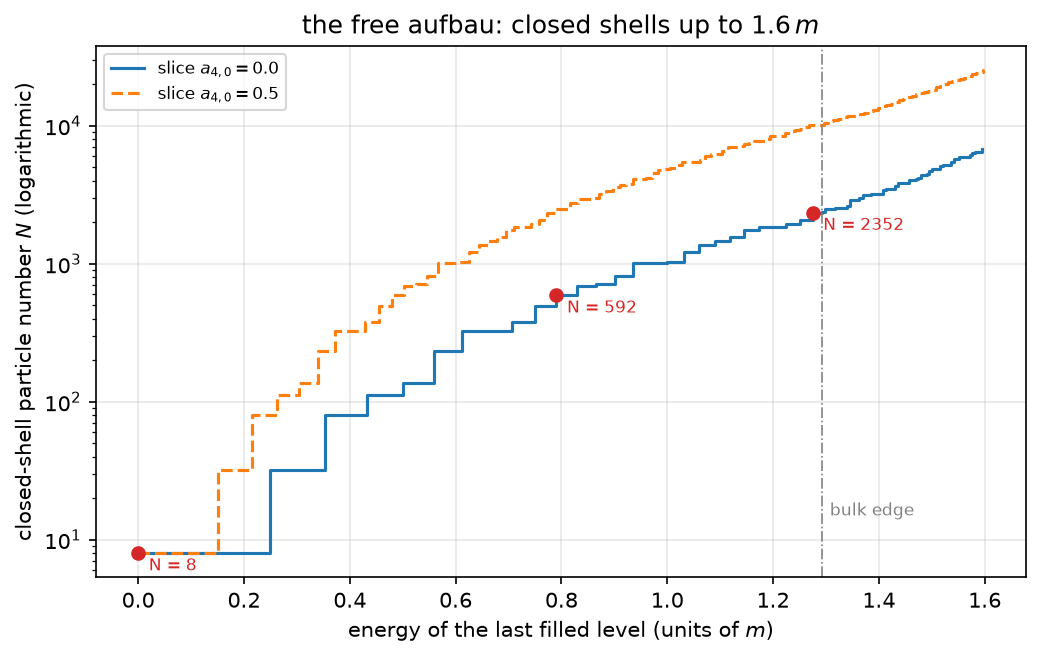

Figure 14c.6 saved as Revision/textbook/figures/14c_6_closed_shells.png


In [15]:
fig, ax = plt.subplots(figsize=(8.0, 4.6))
for a_, style in ((0.0, "-"), (0.5, "--")):
    energies = [t[1] for t in tables[a_]]
    counts = [t[0] for t in tables[a_]]
    ax.step(energies, counts, style, where="post",
            label=f"slice $a_{{4,0}} = {a_}$")
ax.axvline(bulk_edge, color="gray", linestyle="-.", linewidth=0.8)
ax.annotate("bulk edge", (bulk_edge + 0.015, 15), fontsize=8, color="gray")
last_filled = {t[0]: t[1] for t in tables[0.0]}  # N -> its last filled level
for n_ in (8, N_mid, N_large):
    t_ = last_filled[n_]
    ax.plot([t_], [n_], "o", color="C3")
    ax.annotate(f"N = {n_}", (t_ + 0.02, n_ * 0.75), fontsize=8, color="C3")
ax.set_yscale("log")
ax.set_xlabel("energy of the last filled level (units of $m$)")
ax.set_ylabel("closed-shell particle number $N$ (logarithmic)")
ax.set_title("the free aufbau: closed shells up to $1.6\\,m$")
ax.legend(fontsize=8, loc="upper left")
save_figure(fig, "closed_shells",
            "The closed shells of the free aufbau: the particle number $N$ "
            "(logarithmic axis) against the energy of the last filled level "
            "(units of $m$), at the slices $a_{4,0} = 0$ (solid) and $0.5$ "
            "(dashed), for $m = 1$, $L = 3$, $\\Delta k = 0.25$. Each step is one "
            "group of degenerate levels; the red dots mark the particle numbers "
            "$N = 8$ (the zero modes), $592$ and $2352$ of the Revision runs; "
            "$2352$ is the last closed shell below the bulk edge $1.2923\\,m$ "
            "(dash-dotted line); at the later slice the redshifted fold band holds "
            "many more particles below the same energy.")

## 12. The last check

The last cell checks that the six figure files exist and prints the number of
checks that passed.

In [16]:
figure_names = ["14c_1_band_structure.png", "14c_2_band_slope.png",
                "14c_3_band_redshift.png", "14c_4_block_type_mirror.png",
                "14c_5_tip_angle.png", "14c_6_closed_shells.png"]
check(all(output_file(f"{FIGURE_FOLDER}/{name}").is_file() for name in figure_names),
      "all six figure files of this notebook exist")
all_checks_passed()

PASS all six figure files of this notebook exist
ALL 16 CHECKS PASSED (notebook 14c)


## 13. What this notebook showed

- The eight zero modes become the fold band when the 3-momentum is switched on;
  the band is EXACTLY $\varepsilon = \kappa k$ with the orbital $(e^{fMy}, 0)$,
  for every $k$, $M$, $L$ and slice; its slope is $\kappa = e^{-a_{4,0}}$ (PROVED
  by the exact solution and by the Hellmann-Feynman rule; COMPUTED numerically
  at all five slices and for six masses and cutoffs; the values reproduce the
  Rust solver's records).
- Along the PRESCRIBED deflating history every level obeys the exact rescaling
  relation $\varepsilon(k, a_{4,0}; L) = \varepsilon(k e^{-a_{4,0}}, 0; f_0L)$:
  the band is redshifted, and the gap of the free $N = 8$ state is
  $\kappa\Delta k = 0.25\,e^{-a_{4,0}}$, from $0.25\,m$ at $a_{4,0} = 0$ to
  $0.0338\,m$ at $a_{4,0} = 2$, while the levels away from the band rise.
- The two block types have mirrored spectra, $\mathrm{spec}\,h_{-1} =
  -\mathrm{spec}\,h_{+1}$, and $\sigma_3$ maps $(j, k)$ to $(-j, -k)$.
- The tip angle shifts a level by an amount fixed by the exact boundary
  identity: the fold band moves by at most $0.033\,m$ (its tail at the tip), the
  extended levels by $0.06\,m$ or more (nothing suppresses them toward the tip).
  The cutoff is a choice of the numerical model.
- With the CONVENTION that the positive free levels and the zero modes are
  particle levels (its justification is OPEN), the free aufbau has the closed
  shells $8, 32, 80, 112, 136, \dots, 2352$ below the bulk edge $1.2923\,m$;
  the Revision runs use $N = 8, 592, 2352$ (reproduced from the rule).
- ASSUMED: both fold conditions filled. CHOSEN: the regular tip at $L = 3$.